In [1]:
# If any package is missing, uncomment the line below and run once:
# !pip install numpy pandas matplotlib seaborn scikit-learn scipy

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing & Dimensionality Reduction (Lectures 13, 14, 16)
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.manifold import TSNE, trustworthiness

# Neural Network / Autoencoder (Lecture 19)
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# Clustering & Evaluation (Lectures 20, 21)
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, MeanShift, estimate_bandwidth, OPTICS
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from scipy.cluster.hierarchy import dendrogram, linkage

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('viridis')

# Project Base Directory (Full Path)
BASE_DIR = r'E:\DA_Project'
SELLERS_PATH = os.path.join(BASE_DIR, 'master_sellers.csv')

# Set random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Load master_sellers.csv using full path
df_sellers = pd.read_csv(SELLERS_PATH)

print(f"Loaded {SELLERS_PATH} successfully! Shape: {df_sellers.shape}")
print("\nColumns and Data Types:")
print(df_sellers.dtypes)
df_sellers.head()

Loaded E:\DA_Project\master_sellers.csv successfully! Shape: (3095, 25)

Columns and Data Types:
seller_id                    object
total_orders                  int64
total_items                   int64
total_revenue               float64
total_freight               float64
avg_price                   float64
avg_freight                 float64
avg_weight_g                float64
avg_handling_days           float64
median_handling_days        float64
avg_transit_days            float64
avg_delivery_days           float64
avg_days_late               float64
late_rate                   float64
seller_shipped_late_rate    float64
avg_review_score            float64
low_review_rate             float64
distinct_categories           int64
states_served                 int64
avg_distance_km             float64
seller_zip_code_prefix        int64
seller_city                  object
seller_state                 object
freight_ratio               float64
cross_state_share           float64
dty

,seller_id,total_orders,total_items,total_revenue,total_freight,avg_price,avg_freight,avg_weight_g,avg_handling_days,median_handling_days,...,avg_review_score,low_review_rate,distinct_categories,states_served,avg_distance_km,seller_zip_code_prefix,seller_city,seller_state,freight_ratio,cross_state_share
0,0015a82c2db000af6aaaf3ae2ecb0532,3,3,2685.00,63.06,895.000000,21.020000,11800.000000,2.804352,1.728322,...,3.666667,0.333333,1,2,606.589740,9080,santo andre,SP,0.023486,1.000000
1,001cca7ae9ae17fb1caed9dfb1094831,200,239,25080.03,8854.14,104.937364,37.046611,8973.849372,2.179816,1.671863,...,3.902542,0.188285,2,18,807.971737,29156,cariacica,ES,0.353035,0.974895
2,001e6ad469a905060d959994f1b41e4f,1,1,250.00,17.94,250.000000,17.940000,750.000000,NaN,NaN,...,1.000000,1.000000,1,1,394.481094,24754,sao goncalo,RJ,0.071760,1.000000
3,002100f778ceb8431b7a1020ff7ab48f,51,55,1234.50,793.66,22.445455,14.430182,331.818182,3.542166,2.733380,...,3.981818,0.145455,1,13,517.647972,14405,franca,SP,0.642900,0.563636
4,003554e2dce176b5555353e4f3555ac8,1,1,120.00,19.38,120.000000,19.380000,1200.000000,0.523623,0.523623,...,5.000000,0.000000,1,1,936.393081,74565,goiania,GO,0.161500,1.000000


In [2]:
# ==============================================================================
# CELL 2: FEATURE SELECTION, LOG-TRANSFORMATION, IMPUTATION & SCALING
# ==============================================================================

# 1. Separate Metadata / Identifiers from Behavioral Features
meta_cols = ['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state']
feature_cols = [c for c in df_sellers.columns if c not in meta_cols]

print(f"Total behavioral features selected: {len(feature_cols)}")
print("\nMissing values per feature before imputation:")
missing_counts = df_sellers[feature_cols].isnull().sum()
print(missing_counts[missing_counts > 0])

# 2. Impute missing values using median (robust to skewed distributions)
imputer = SimpleImputer(strategy='median')
X_imputed = pd.DataFrame(
    imputer.fit_transform(df_sellers[feature_cols]),
    columns=feature_cols,
    index=df_sellers.index
)

# 3. Log1p transform heavily right-skewed positive features
skewed_cols = [
    'total_orders', 'total_items', 'total_revenue', 'total_freight',
    'avg_price', 'avg_freight', 'avg_weight_g',
    'distinct_categories', 'states_served', 'freight_ratio'
]

X_transformed = X_imputed.copy()
for col in skewed_cols:
    # Clip at 0 just in case before log1p
    X_transformed[col] = np.log1p(np.clip(X_transformed[col], a_min=0, a_max=None))

# 4. Standardize all features to Mean=0, Std=1
scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X_transformed),
    columns=feature_cols,
    index=df_sellers.index
)

print(f"\nScaled feature matrix X_scaled ready! Shape: {X_scaled.shape}")
print(f"Any NaNs remaining: {X_scaled.isnull().sum().sum()}")
X_scaled.describe().T[['mean', 'std', 'min', 'max']].round(2)

Total behavioral features selected: 21

Missing values per feature before imputation:
avg_handling_days       118
median_handling_days    118
avg_transit_days        125
avg_delivery_days       125
avg_days_late           125
late_rate               125
avg_review_score          5
low_review_rate           5
avg_distance_km           5
dtype: int64

Scaled feature matrix X_scaled ready! Shape: (3095, 21)
Any NaNs remaining: 0


,mean,std,min,max
total_orders,0.0,1.0,-1.15,3.83
total_items,-0.0,1.0,-1.20,3.76
total_revenue,0.0,1.0,-2.85,3.04
total_freight,-0.0,1.0,-1.90,3.48
avg_price,-0.0,1.0,-3.25,4.37
avg_freight,0.0,1.0,-4.74,5.64
avg_weight_g,0.0,1.0,-2.43,2.62
avg_handling_days,0.0,1.0,-5.44,14.98
median_handling_days,0.0,1.0,-1.40,15.60
avg_transit_days,0.0,1.0,-2.40,31.85


## Running PCA and SVD on seller feature

=== LECTURE 12 & 13: PCA EIGEN-DECOMPOSITION SUMMARY ===
Orthogonality check ||W^T W - I||_max = 2.78e-15
PC01: Eigenvalue (lambda) =  5.290 | Variance = 25.18% | Cumulative CV(k) =  25.18%
PC02: Eigenvalue (lambda) =  4.178 | Variance = 19.89% | Cumulative CV(k) =  45.07%
PC03: Eigenvalue (lambda) =  2.717 | Variance = 12.93% | Cumulative CV(k) =  58.01%
PC04: Eigenvalue (lambda) =  1.889 | Variance =  8.99% | Cumulative CV(k) =  67.00%
PC05: Eigenvalue (lambda) =  1.634 | Variance =  7.78% | Cumulative CV(k) =  74.78%
PC06: Eigenvalue (lambda) =  1.506 | Variance =  7.17% | Cumulative CV(k) =  81.94%
PC07: Eigenvalue (lambda) =  0.985 | Variance =  4.69% | Cumulative CV(k) =  86.64%
PC08: Eigenvalue (lambda) =  0.586 | Variance =  2.79% | Cumulative CV(k) =  89.43%
PC09: Eigenvalue (lambda) =  0.531 | Variance =  2.53% | Cumulative CV(k) =  91.95%
PC10: Eigenvalue (lambda) =  0.426 | Variance =  2.03% | Cumulative CV(k) =  93.98%

Threshold Summary: 80% needs k = 6 | 90% needs k = 9 

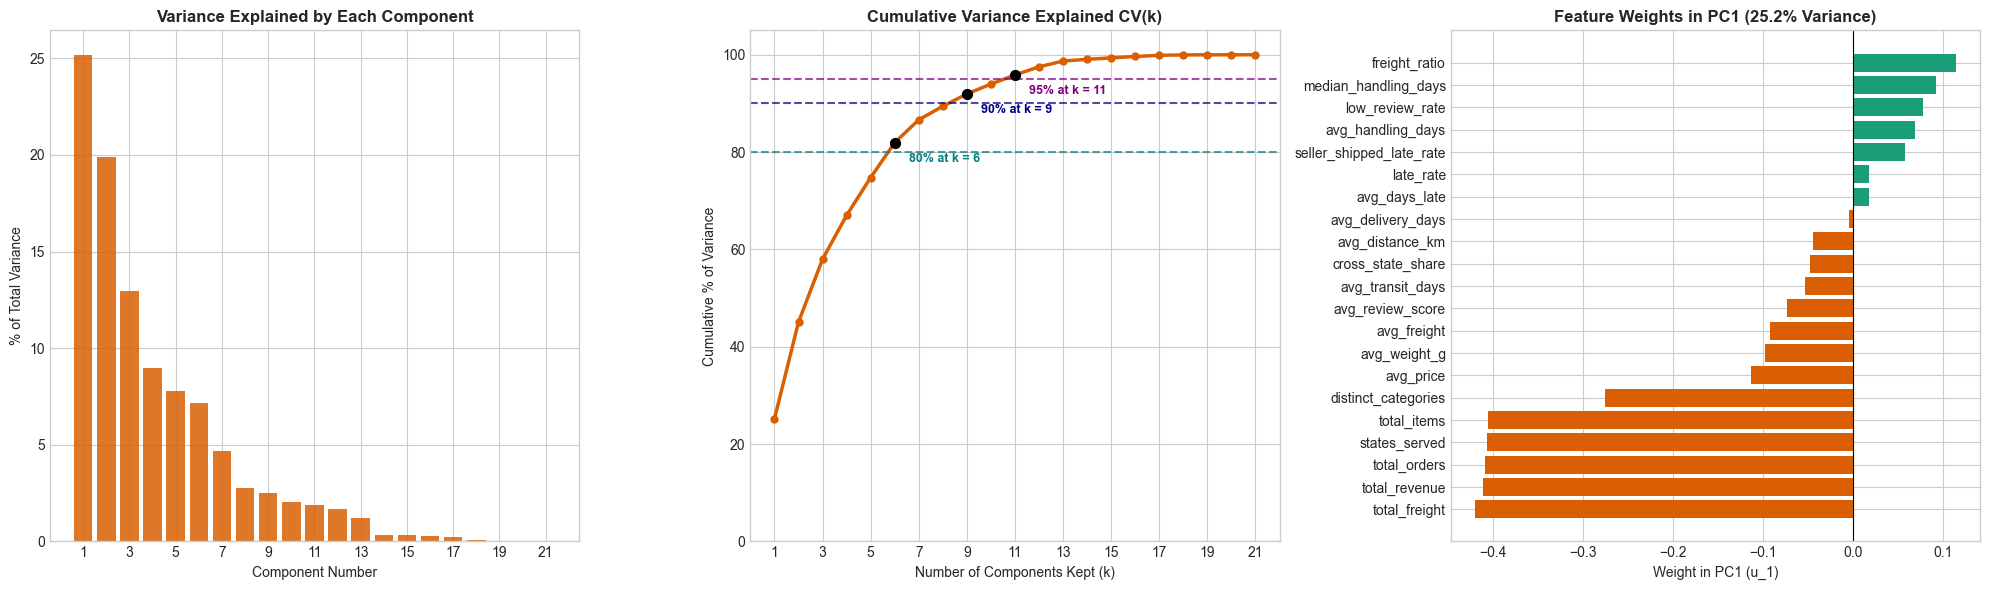

In [3]:
# ==============================================================================
# CELL 3: PCA & SVD (ALIGNED WITH LECTURE 12 & LECTURE 13 FORMULAS)
# ==============================================================================

X_mat = X_scaled.values
n_samples, n_features = X_mat.shape

# ------------------------------------------------------------------------------
# PART A: PCA VIA COVARIANCE EIGEN-DECOMPOSITION (LECTURE 12 STEPS 1-4)
# ------------------------------------------------------------------------------
# Step 1: Data is already centered & standardized (X_scaled has mean=0, std=1)
# Step 2: Covariance matrix C = (1 / (n - 1)) * X^T X
C = np.cov(X_mat, rowvar=False)

# Step 3: Eigenvalues and eigenvectors of symmetric C (eigh returns ascending, so reverse)
eig_vals, eig_vecs = np.linalg.eigh(C)
idx = np.argsort(eig_vals)[::-1]
eig_vals = eig_vals[idx]          # lambda_1 >= lambda_2 >= ... >= lambda_d
W = eig_vecs[:, idx]              # Orthogonal rotation matrix W = [u_1, ..., u_d]

# Verify orthogonality: W^T W = I
ortho_err = np.max(np.abs(W.T @ W - np.eye(n_features)))

# Cumulative Variance Ratio: CV(k) = sum_{i=1}^k lambda_i / sum_{j=1}^d lambda_j
explained_var_ratio = eig_vals / np.sum(eig_vals)
cum_var_ratio = np.cumsum(explained_var_ratio)

k_80 = int(np.argmax(cum_var_ratio >= 0.80) + 1)
k_90 = int(np.argmax(cum_var_ratio >= 0.90) + 1)
k_95 = int(np.argmax(cum_var_ratio >= 0.95) + 1)

print("=== LECTURE 12 & 13: PCA EIGEN-DECOMPOSITION SUMMARY ===")
print(f"Orthogonality check ||W^T W - I||_max = {ortho_err:.2e}")
for i in range(10):
    print(f"PC{i+1:02d}: Eigenvalue (lambda) = {eig_vals[i]:6.3f} | "
          f"Variance = {explained_var_ratio[i]*100:5.2f}% | "
          f"Cumulative CV(k) = {cum_var_ratio[i]*100:6.2f}%")

print(f"\nThreshold Summary: 80% needs k = {k_80} | 90% needs k = {k_90} | 95% needs k = {k_95}")

# ------------------------------------------------------------------------------
# PART B: PCA USING SVD: X = U * S * V^T (LECTURE 13 SLIDES 9-14)
# ------------------------------------------------------------------------------
# Factorize centered matrix X directly without forming C
U, S, Vt = np.linalg.svd(X_mat, full_matrices=False)
V = Vt.T  # Columns of V are right singular vectors (feature directional axes)

# Lecture 13 Slide 14 Mapping:
# 1. Eigenvalues from singular values: lambda_i = sigma_i^2 / (n - 1)
eig_vals_from_svd = (S ** 2) / (n_samples - 1)
# 2. Explained variance ratio: sigma_i^2 / sum(sigma_j^2)
svd_var_ratio = (S ** 2) / np.sum(S ** 2)
# 3. Principal directions u_i^pca = v_i (up to +/- sign flip)
direction_cosines = np.abs(np.diag(W.T @ V))

print("\n===  SVD -> PCA MATHEMATICAL EQUIVALENCE ===")
print(f"Max diff between Covariance eigenvalues and SVD (sigma^2 / (n-1)): "
      f"{np.max(np.abs(eig_vals - eig_vals_from_svd)):.2e}")
print(f"Min |cos(theta)| between PCA eigenvectors (W) and SVD right singular vectors (V): "
      f"{np.min(direction_cosines):.6f} (1.0 = identical directions)")

# ------------------------------------------------------------------------------
# PART C: PROJECTION Y = X W_k & QUANTIFYING DATA LOSS (LECTURE 13 SLIDE 5)
# ------------------------------------------------------------------------------
# Keep k_90 components (90% variance threshold)
k_chosen = k_90
W_k = W[:, :k_chosen]
Y_pca = X_mat @ W_k                        # Compressed dataset Y (n x k)
X_reconstructed = Y_pca @ W_k.T            # Reverse transformation: X_hat = Y W_k^T

# Lecture 13 Slide 5 formula: Data Loss = sum_{i=k+1}^d lambda_i
theoretical_loss = np.sum(eig_vals[k_chosen:])
empirical_mse_sum = np.mean(np.sum((X_mat - X_reconstructed) ** 2, axis=1)) * (n_samples / (n_samples - 1))
reconstruction_mse = mean_squared_error(X_mat, X_reconstructed)

print(f"\n=== PROJECTION & RECONSTRUCTION LOSS AT k = {k_chosen} (90% VARIANCE) ===")
print(f"Compressed shape Y = X W_k: {Y_pca.shape}")
print(f"Theoretical Data Loss sum_{{i=k+1}}^d lambda_i : {theoretical_loss:.4f}")
print(f"Mean Squared Reconstruction Error (per feature)  : {reconstruction_mse:.4f}")

# Inspect Feature Weights (Loadings) for PC1, PC2, PC3 (Lecture 13 Slide 15)
loadings_df = pd.DataFrame(W[:, :3], columns=['PC1', 'PC2', 'PC3'], index=feature_cols)
print("\n=== TOP FEATURE WEIGHTS IN PC1, PC2, PC3 ===")
for pc in ['PC1', 'PC2', 'PC3']:
    top_feats = loadings_df[pc].reindex(loadings_df[pc].abs().sort_values(ascending=False).index).head(5)
    print(f"{pc}: " + ", ".join([f"{feat} ({val:+.3f})" for feat, val in top_feats.items()]))

# ------------------------------------------------------------------------------
# PART D: VISUALIZATION (SCREE PLOT, CUMULATIVE VARIANCE & PC1 WEIGHTS)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
comps = np.arange(1, n_features + 1)

# Plot 1: Variance explained by each component (Lecture 13 Slide 8 style)
axes[0].bar(comps, explained_var_ratio * 100, color='#d95f02', alpha=0.85)
axes[0].set_title('Variance Explained by Each Component', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Component Number')
axes[0].set_ylabel('% of Total Variance')
axes[0].set_xticks(comps[::2])

# Plot 2: Cumulative variance explained with 80%, 90%, 95% markers
axes[1].plot(comps, cum_var_ratio * 100, color='#d95f02', linewidth=2.5, marker='o', markersize=5)
for thresh, k_val, col in [(80, k_80, 'teal'), (90, k_90, 'navy'), (95, k_95, 'purple')]:
    axes[1].axhline(thresh, color=col, linestyle='--', alpha=0.7)
    axes[1].scatter([k_val], [cum_var_ratio[k_val-1]*100], color='black', zorder=5, s=50)
    axes[1].annotate(f"{thresh}% at k = {k_val}",
                     xy=(k_val, cum_var_ratio[k_val-1]*100),
                     xytext=(k_val + 0.6, cum_var_ratio[k_val-1]*100 - 4),
                     fontsize=9, fontweight='bold', color=col)
axes[1].set_title('Cumulative Variance Explained CV(k)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Number of Components Kept (k)')
axes[1].set_ylabel('Cumulative % of Variance')
axes[1].set_xticks(comps[::2])
axes[1].set_ylim(0, 105)

# Plot 3: Feature Weights in PC1 (Lecture 13 Slide 15 style)
pc1_sorted = loadings_df['PC1'].sort_values()
colors = ['#d95f02' if v < 0 else '#1b9e77' for v in pc1_sorted]
axes[2].barh(pc1_sorted.index, pc1_sorted.values, color=colors)
axes[2].axvline(0, color='black', linewidth=0.8)
axes[2].set_title(f'Feature Weights in PC1 ({explained_var_ratio[0]*100:.1f}% Variance)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Weight in PC1 (u_1)')

plt.tight_layout()
pca_svd_fig_path = os.path.join(BASE_DIR, 'pca_svd_lecture13.png')
plt.savefig(pca_svd_fig_path, dpi=300, bbox_inches='tight')
print(f"\nSaved figure to: {pca_svd_fig_path}")
plt.show()

## T-SNE

=== RUNNING t-SNE PERPLEXITY SWEEP (n = 3,095 SELLERS) ===
Perplexity =   5 | Trustworthiness (k=10): 0.9708 | Trustworthiness (k=30): 0.9295 | KL Divergence: 1.5840
Perplexity =  15 | Trustworthiness (k=10): 0.9798 | Trustworthiness (k=30): 0.9476 | KL Divergence: 1.6970
Perplexity =  30 | Trustworthiness (k=10): 0.9794 | Trustworthiness (k=30): 0.9524 | KL Divergence: 1.6369
Perplexity =  50 | Trustworthiness (k=10): 0.9772 | Trustworthiness (k=30): 0.9530 | KL Divergence: 1.5485
Perplexity = 100 | Trustworthiness (k=10): 0.9754 | Trustworthiness (k=30): 0.9553 | KL Divergence: 1.3633

Optimal Perplexity by Local Trustworthiness (k=10): Perplexity = 15 (Score = 0.9798)
Baseline 2D PCA   | Trustworthiness (k=10): 0.8058 | Trustworthiness (k=30): 0.8061

Saved t-SNE sweep grid to: E:\DA_Project\tsne_perplexity_sweep.png


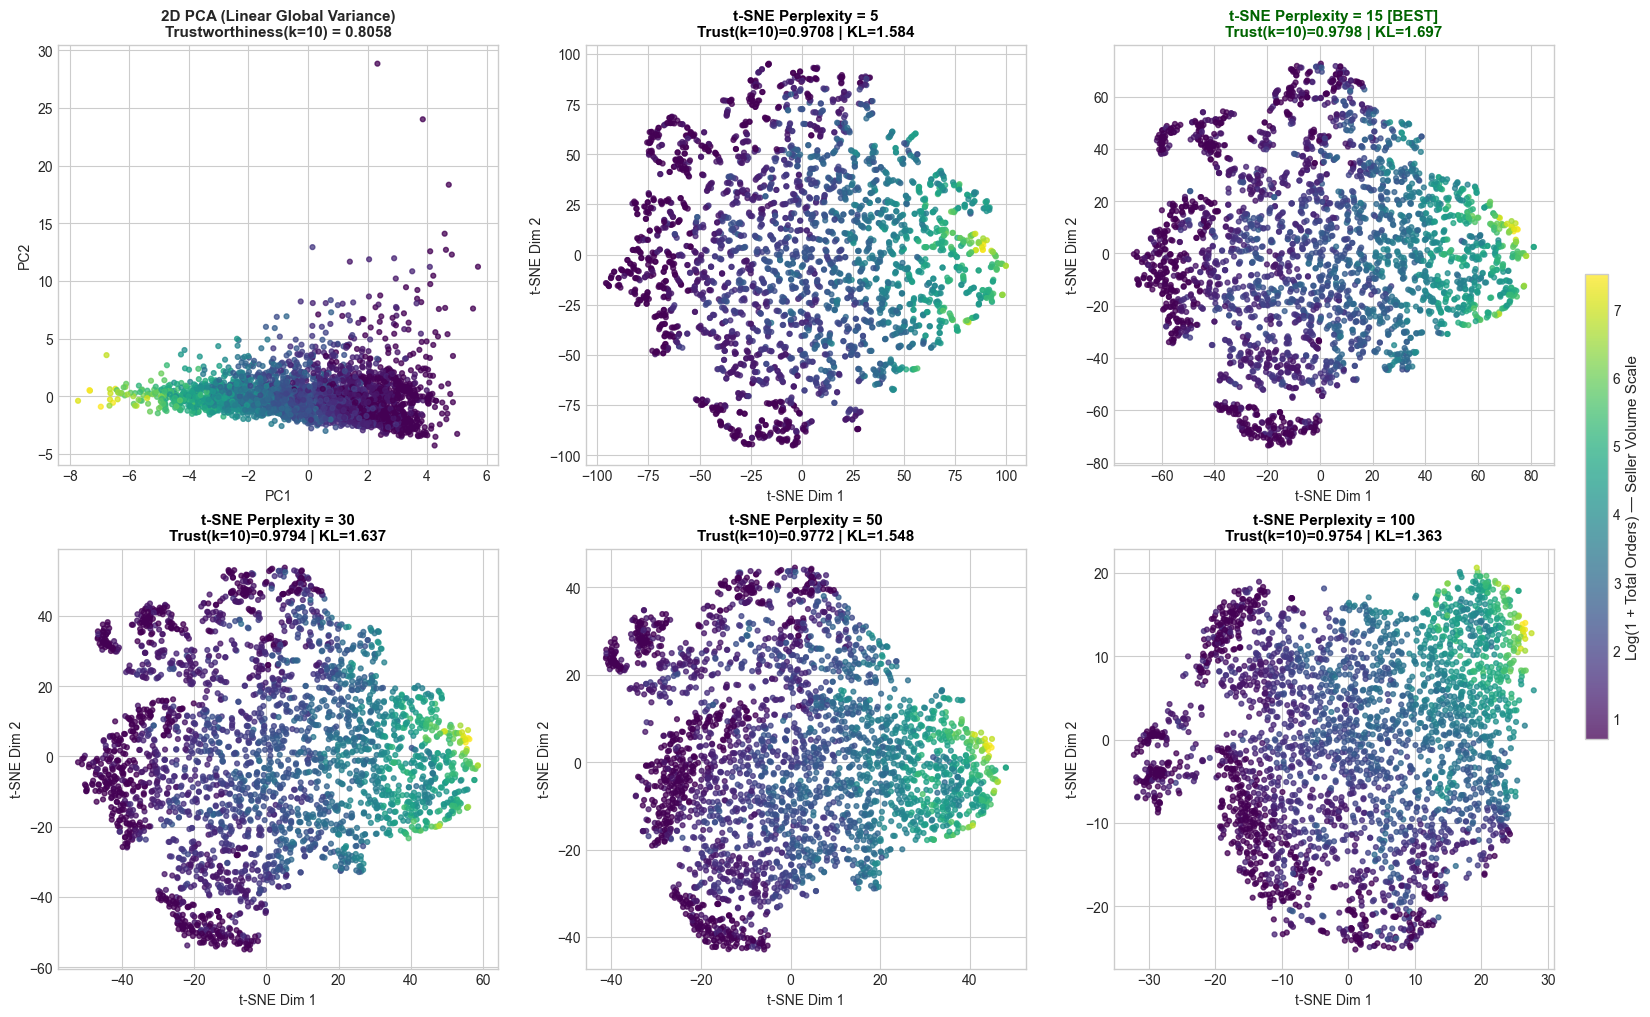

Saved trustworthiness curve to: E:\DA_Project\tsne_trustworthiness_curve.png


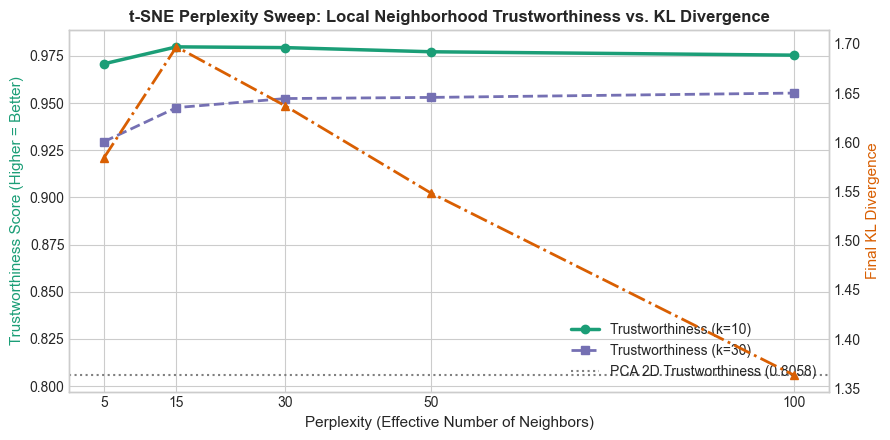

In [5]:
# ==============================================================================
# CELL 4: t-SNE PERPLEXITY SWEEP WITH TRUSTWORTHINESS SCORES (LECTURE 14)
# ==============================================================================
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"  # Fix Windows 11 wmic physical core lookup

perplexities = [5, 15, 30, 50, 100]
tsne_results = {}
sweep_metrics = []

print("=== RUNNING t-SNE PERPLEXITY SWEEP (n = 3,095 SELLERS) ===")
for perp in perplexities:
    tsne = TSNE(
        n_components=2,
        perplexity=perp,
        init='pca',              # Standard initialization for reproducible convergence
        learning_rate='auto',
        max_iter=1000,
        random_state=RANDOM_STATE
    )
    Y_tsne = tsne.fit_transform(X_mat)
    tsne_results[perp] = Y_tsne

    # Quantitative neighborhood preservation metrics (Trustworthiness in [0, 1])
    trust_10 = trustworthiness(X_mat, Y_tsne, n_neighbors=10)
    trust_30 = trustworthiness(X_mat, Y_tsne, n_neighbors=30)
    kl_div = tsne.kl_divergence_

    sweep_metrics.append({
        'Perplexity': perp,
        'Trustworthiness (k=10)': round(trust_10, 4),
        'Trustworthiness (k=30)': round(trust_30, 4),
        'Final KL Divergence': round(kl_div, 4)
    })
    print(f"Perplexity = {perp:3d} | Trustworthiness (k=10): {trust_10:.4f} | "
          f"Trustworthiness (k=30): {trust_30:.4f} | KL Divergence: {kl_div:.4f}")

# Summary Table & Optimal Perplexity Selection
tsne_eval_df = pd.DataFrame(sweep_metrics)
best_row = tsne_eval_df.loc[tsne_eval_df['Trustworthiness (k=10)'].idxmax()]
best_perp = int(best_row['Perplexity'])
print(f"\nOptimal Perplexity by Local Trustworthiness (k=10): Perplexity = {best_perp} "
      f"(Score = {best_row['Trustworthiness (k=10)']:.4f})")

# Also compute PCA 2D Trustworthiness for direct Lecture 14 comparison (Global vs Local)
Y_pca_2d = X_mat @ W[:, :2]
pca_trust_10 = trustworthiness(X_mat, Y_pca_2d, n_neighbors=10)
pca_trust_30 = trustworthiness(X_mat, Y_pca_2d, n_neighbors=30)
print(f"Baseline 2D PCA   | Trustworthiness (k=10): {pca_trust_10:.4f} | "
      f"Trustworthiness (k=30): {pca_trust_30:.4f}")

# ------------------------------------------------------------------------------
# VISUALIZATION: 2x3 GRID (PCA 2D + 5 PERPLEXITIES) & TRUSTWORTHINESS CURVE
# ------------------------------------------------------------------------------
color_metric = X_transformed['total_orders']

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

# Panel 0: 2D PCA Baseline (Global Structure)
sc0 = axes[0].scatter(Y_pca_2d[:, 0], Y_pca_2d[:, 1], c=color_metric, cmap='viridis', s=12, alpha=0.75)
axes[0].set_title(f'2D PCA (Linear Global Variance)\nTrustworthiness(k=10) = {pca_trust_10:.4f}',
                  fontsize=11, fontweight='bold')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

# Panels 1-5: t-SNE across Perplexity = [5, 15, 30, 50, 100]
for idx, perp in enumerate(perplexities, start=1):
    emb = tsne_results[perp]
    row = tsne_eval_df[tsne_eval_df['Perplexity'] == perp].iloc[0]
    sc = axes[idx].scatter(emb[:, 0], emb[:, 1], c=color_metric, cmap='viridis', s=12, alpha=0.75)
    title_tag = " [BEST]" if perp == best_perp else ""
    axes[idx].set_title(
        f"t-SNE Perplexity = {perp}{title_tag}\n"
        f"Trust(k=10)={row['Trustworthiness (k=10)']:.4f} | KL={row['Final KL Divergence']:.3f}",
        fontsize=11, fontweight='bold',
        color='darkgreen' if perp == best_perp else 'black'
    )
    axes[idx].set_xlabel('t-SNE Dim 1')
    axes[idx].set_ylabel('t-SNE Dim 2')

cbar = fig.colorbar(sc, ax=axes, orientation='vertical', fraction=0.015, pad=0.02)
cbar.set_label('Log(1 + Total Orders) — Seller Volume Scale', fontsize=11)

tsne_grid_path = os.path.join(BASE_DIR, 'tsne_perplexity_sweep.png')
plt.savefig(tsne_grid_path, dpi=300, bbox_inches='tight')
print(f"\nSaved t-SNE sweep grid to: {tsne_grid_path}")
plt.show()

# Plot Trustworthiness & KL Divergence Trade-off Curve
fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax1.plot(tsne_eval_df['Perplexity'], tsne_eval_df['Trustworthiness (k=10)'], 'o-', color='#1b9e77', linewidth=2.5, label='Trustworthiness (k=10)')
ax1.plot(tsne_eval_df['Perplexity'], tsne_eval_df['Trustworthiness (k=30)'], 's--', color='#7570b3', linewidth=2, label='Trustworthiness (k=30)')
ax1.axhline(pca_trust_10, color='gray', linestyle=':', label=f'PCA 2D Trustworthiness ({pca_trust_10:.4f})')
ax1.set_xlabel('Perplexity (Effective Number of Neighbors)', fontsize=11)
ax1.set_ylabel('Trustworthiness Score (Higher = Better)', fontsize=11, color='#1b9e77')
ax1.set_xticks(perplexities)
ax1.legend(loc='lower right')

ax2 = ax1.twinx()
ax2.plot(tsne_eval_df['Perplexity'], tsne_eval_df['Final KL Divergence'], '^-.', color='#d95f02', linewidth=2, label='Final KL Divergence')
ax2.set_ylabel('Final KL Divergence', fontsize=11, color='#d95f02')
ax2.grid(False)

plt.title('t-SNE Perplexity Sweep: Local Neighborhood Trustworthiness vs. KL Divergence', fontsize=12, fontweight='bold')
plt.tight_layout()
tsne_curve_path = os.path.join(BASE_DIR, 'tsne_trustworthiness_curve.png')
plt.savefig(tsne_curve_path, dpi=300, bbox_inches='tight')
print(f"Saved trustworthiness curve to: {tsne_curve_path}")
plt.show()

## Auto encoder Training

Autoencoder Train set: (2476, 21) | Unseen Test set: (619, 21)

=== COMPARING RECONSTRUCTION MSE: LINEAR PCA vs. NON-LINEAR AUTOENCODER ===
k =  2 | PCA Test MSE: 0.5255 | AE Test MSE: 0.4044 | Non-Linear Gain: +23.05%
k =  3 | PCA Test MSE: 0.4052 | AE Test MSE: 0.3001 | Non-Linear Gain: +25.94%
k =  6 | PCA Test MSE: 0.1808 | AE Test MSE: 0.1116 | Non-Linear Gain: +38.28%
k =  9 | PCA Test MSE: 0.0816 | AE Test MSE: 0.0684 | Non-Linear Gain: +16.10%

=== SUMMARY TABLE: PCA vs. AUTOENCODER RECONSTRUCTION ERROR ===
 Bottleneck (k)  PCA Train MSE  AE Train MSE  PCA Test MSE  AE Test MSE  Test MSE Reduction (%)
              2         0.5557        0.3796        0.5255       0.4044                   23.05
              3         0.4241        0.2749        0.4052       0.3001                   25.94
              6         0.1810        0.1057        0.1808       0.1116                   38.28
              9         0.0805        0.0662        0.0816       0.0684                   16.10

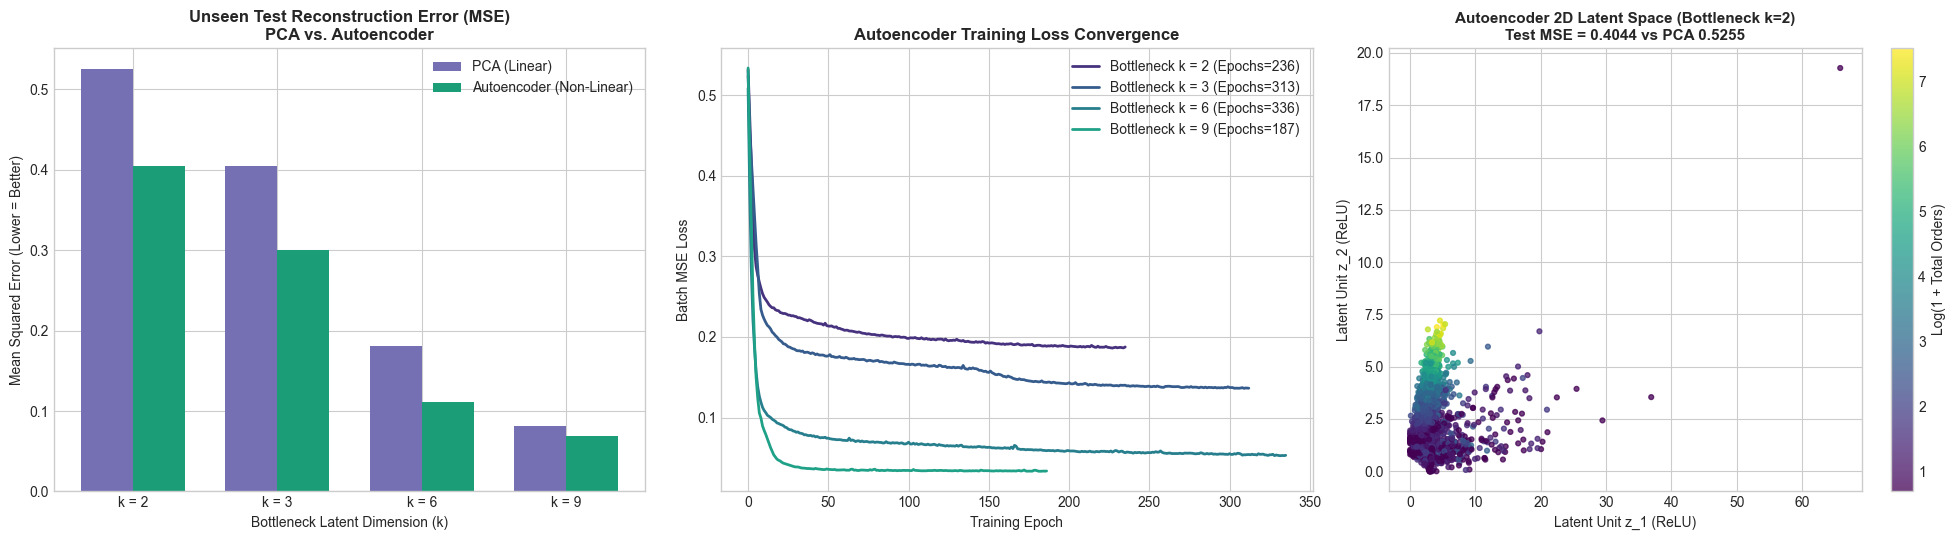

In [6]:
# ==============================================================================
# CELL 5: AUTOENCODER TRAINING & RECONSTRUCTION ERROR vs. PCA (LECTURE 17)
# ==============================================================================

# 1. Train / Test Split (80% Train, 20% Unseen Test) to verify generalization (Slide 25)
X_train, X_test = train_test_split(X_mat, test_size=0.20, random_state=RANDOM_STATE)
print(f"Autoencoder Train set: {X_train.shape} | Unseen Test set: {X_test.shape}")

# Helper: Extract bottleneck latent space Z from trained symmetric MLPRegressor
def encode_latent(mlp_model, X_input, bottleneck_layer_idx):
    """Forward pass through the Encoder layers up to the bottleneck Z."""
    A = X_input
    for layer_idx in range(bottleneck_layer_idx + 1):
        W_layer = mlp_model.coefs_[layer_idx]
        b_layer = mlp_model.intercepts_[layer_idx]
        A = A @ W_layer + b_layer
        # Apply ReLU activation (max(0, A)) as in Lecture 17 Slide 6
        A = np.maximum(0, A)
    return A

# 2. Sweep bottleneck dimensions k in [2, 3, 6, 9] and compare Autoencoder vs. PCA
bottleneck_dims = [2, 3, 6, 9]
comparison_rows = []
ae_models = {}
ae_loss_curves = {}

print("\n=== COMPARING RECONSTRUCTION MSE: LINEAR PCA vs. NON-LINEAR AUTOENCODER ===")
for k in bottleneck_dims:
    # --- A. Linear PCA (Fit on Train, Reconstruct Train & Test) ---
    pca_k = PCA(n_components=k, random_state=RANDOM_STATE)
    pca_k.fit(X_train)
    X_train_pca_hat = pca_k.inverse_transform(pca_k.transform(X_train))
    X_test_pca_hat = pca_k.inverse_transform(pca_k.transform(X_test))

    pca_train_mse = mean_squared_error(X_train, X_train_pca_hat)
    pca_test_mse = mean_squared_error(X_test, X_test_pca_hat)

    # --- B. Symmetric Autoencoder: 21 -> 16 -> k (Bottleneck) -> 16 -> 21 ---
    # ReLU hidden layers + linear output layer (to reconstruct z-scored features)
    ae = MLPRegressor(
        hidden_layer_sizes=(16, k, 16),
        activation='relu',
        solver='adam',
        alpha=1e-4,              # L2 weight regularization to prevent memorization
        batch_size=64,
        learning_rate_init=0.003,
        max_iter=400,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=25,
        random_state=RANDOM_STATE
    )
    ae.fit(X_train, X_train)  # Target = Input (Self-Supervised, Slide 3)

    X_train_ae_hat = ae.predict(X_train)
    X_test_ae_hat = ae.predict(X_test)

    ae_train_mse = mean_squared_error(X_train, X_train_ae_hat)
    ae_test_mse = mean_squared_error(X_test, X_test_ae_hat)
    error_reduction_pct = ((pca_test_mse - ae_test_mse) / pca_test_mse) * 100

    ae_models[k] = ae
    ae_loss_curves[k] = ae.loss_curve_

    comparison_rows.append({
        'Bottleneck (k)': k,
        'PCA Train MSE': round(pca_train_mse, 4),
        'AE Train MSE': round(ae_train_mse, 4),
        'PCA Test MSE': round(pca_test_mse, 4),
        'AE Test MSE': round(ae_test_mse, 4),
        'Test MSE Reduction (%)': round(error_reduction_pct, 2)
    })

    print(f"k = {k:2d} | PCA Test MSE: {pca_test_mse:.4f} | AE Test MSE: {ae_test_mse:.4f} | "
          f"Non-Linear Gain: {error_reduction_pct:+.2f}%")

ae_comp_df = pd.DataFrame(comparison_rows)
print("\n=== SUMMARY TABLE: PCA vs. AUTOENCODER RECONSTRUCTION ERROR ===")
print(ae_comp_df.to_string(index=False))

# 3. Deploy Trained Encoder (k = 6, matching 80%+ PCA variance) to get Latent Space Z
k_ae_best = 6
Z_ae_6d = encode_latent(ae_models[k_ae_best], X_mat, bottleneck_layer_idx=1)
Z_ae_2d = encode_latent(ae_models[2], X_mat, bottleneck_layer_idx=1)
print(f"\nDeployed Trained Encoder (k={k_ae_best}): Latent representation Z shape = {Z_ae_6d.shape}")

# ------------------------------------------------------------------------------
# 4. VISUALIZATION: RECONSTRUCTION MSE COMPARISON, TRAINING LOSS & 2D LATENT SPACE
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

# Panel A: Test Reconstruction Error (PCA vs. Autoencoder across k)
x_idx = np.arange(len(bottleneck_dims))
width = 0.36
axes[0].bar(x_idx - width/2, ae_comp_df['PCA Test MSE'], width, label='PCA (Linear)', color='#7570b3')
axes[0].bar(x_idx + width/2, ae_comp_df['AE Test MSE'], width, label='Autoencoder (Non-Linear)', color='#1b9e77')
axes[0].set_title('Unseen Test Reconstruction Error (MSE)\nPCA vs. Autoencoder', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Bottleneck Latent Dimension (k)')
axes[0].set_ylabel('Mean Squared Error (Lower = Better)')
axes[0].set_xticks(x_idx)
axes[0].set_xticklabels([f"k = {k}" for k in bottleneck_dims])
axes[0].legend()

# Panel B: Autoencoder Training Convergence (MSE Loss Curve)
for k, curve in ae_loss_curves.items():
    axes[1].plot(curve, linewidth=2, label=f'Bottleneck k = {k} (Epochs={len(curve)})')
axes[1].set_title('Autoencoder Training Loss Convergence', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Training Epoch')
axes[1].set_ylabel('Batch MSE Loss')
axes[1].legend()

# Panel C: 2D Autoencoder Latent Space (Bottleneck k=2) colored by Seller Volume
sc = axes[2].scatter(Z_ae_2d[:, 0], Z_ae_2d[:, 1], c=X_transformed['total_orders'], cmap='viridis', s=12, alpha=0.75)
axes[2].set_title(f'Autoencoder 2D Latent Space (Bottleneck k=2)\nTest MSE = {ae_comp_df.loc[0, "AE Test MSE"]:.4f} vs PCA {ae_comp_df.loc[0, "PCA Test MSE"]:.4f}',
                  fontsize=11, fontweight='bold')
axes[2].set_xlabel('Latent Unit z_1 (ReLU)')
axes[2].set_ylabel('Latent Unit z_2 (ReLU)')
plt.colorbar(sc, ax=axes[2], label='Log(1 + Total Orders)')

plt.tight_layout()
ae_fig_path = os.path.join(BASE_DIR, 'autoencoder_vs_pca.png')
plt.savefig(ae_fig_path, dpi=300, bbox_inches='tight')
print(f"\nSaved Autoencoder vs PCA figure to: {ae_fig_path}")
plt.show()

## K- Means Clusteirng

=== RUNNING K-MEANS SWEEP (k = 2 to 10 | init='k-means++', n_init=20) ===
k =  2 | Inertia =  53760.69 | Silhouette = 0.1712 | Davies-Bouldin = 1.8461 | Converged in  8 iters
k =  3 | Inertia =  46948.54 | Silhouette = 0.1900 | Davies-Bouldin = 1.6289 | Converged in 12 iters
k =  4 | Inertia =  42706.43 | Silhouette = 0.1707 | Davies-Bouldin = 1.8399 | Converged in 27 iters
k =  5 | Inertia =  39578.39 | Silhouette = 0.1793 | Davies-Bouldin = 1.7025 | Converged in 22 iters
k =  6 | Inertia =  37497.45 | Silhouette = 0.1606 | Davies-Bouldin = 1.7805 | Converged in 20 iters
k =  7 | Inertia =  35558.57 | Silhouette = 0.1609 | Davies-Bouldin = 1.5454 | Converged in 26 iters
k =  8 | Inertia =  33666.34 | Silhouette = 0.1339 | Davies-Bouldin = 1.5199 | Converged in 21 iters
k =  9 | Inertia =  32010.35 | Silhouette = 0.1382 | Davies-Bouldin = 1.5246 | Converged in 21 iters
k = 10 | Inertia =  30605.94 | Silhouette = 0.1422 | Davies-Bouldin = 1.4705 | Converged in 28 iters

Highest overall 

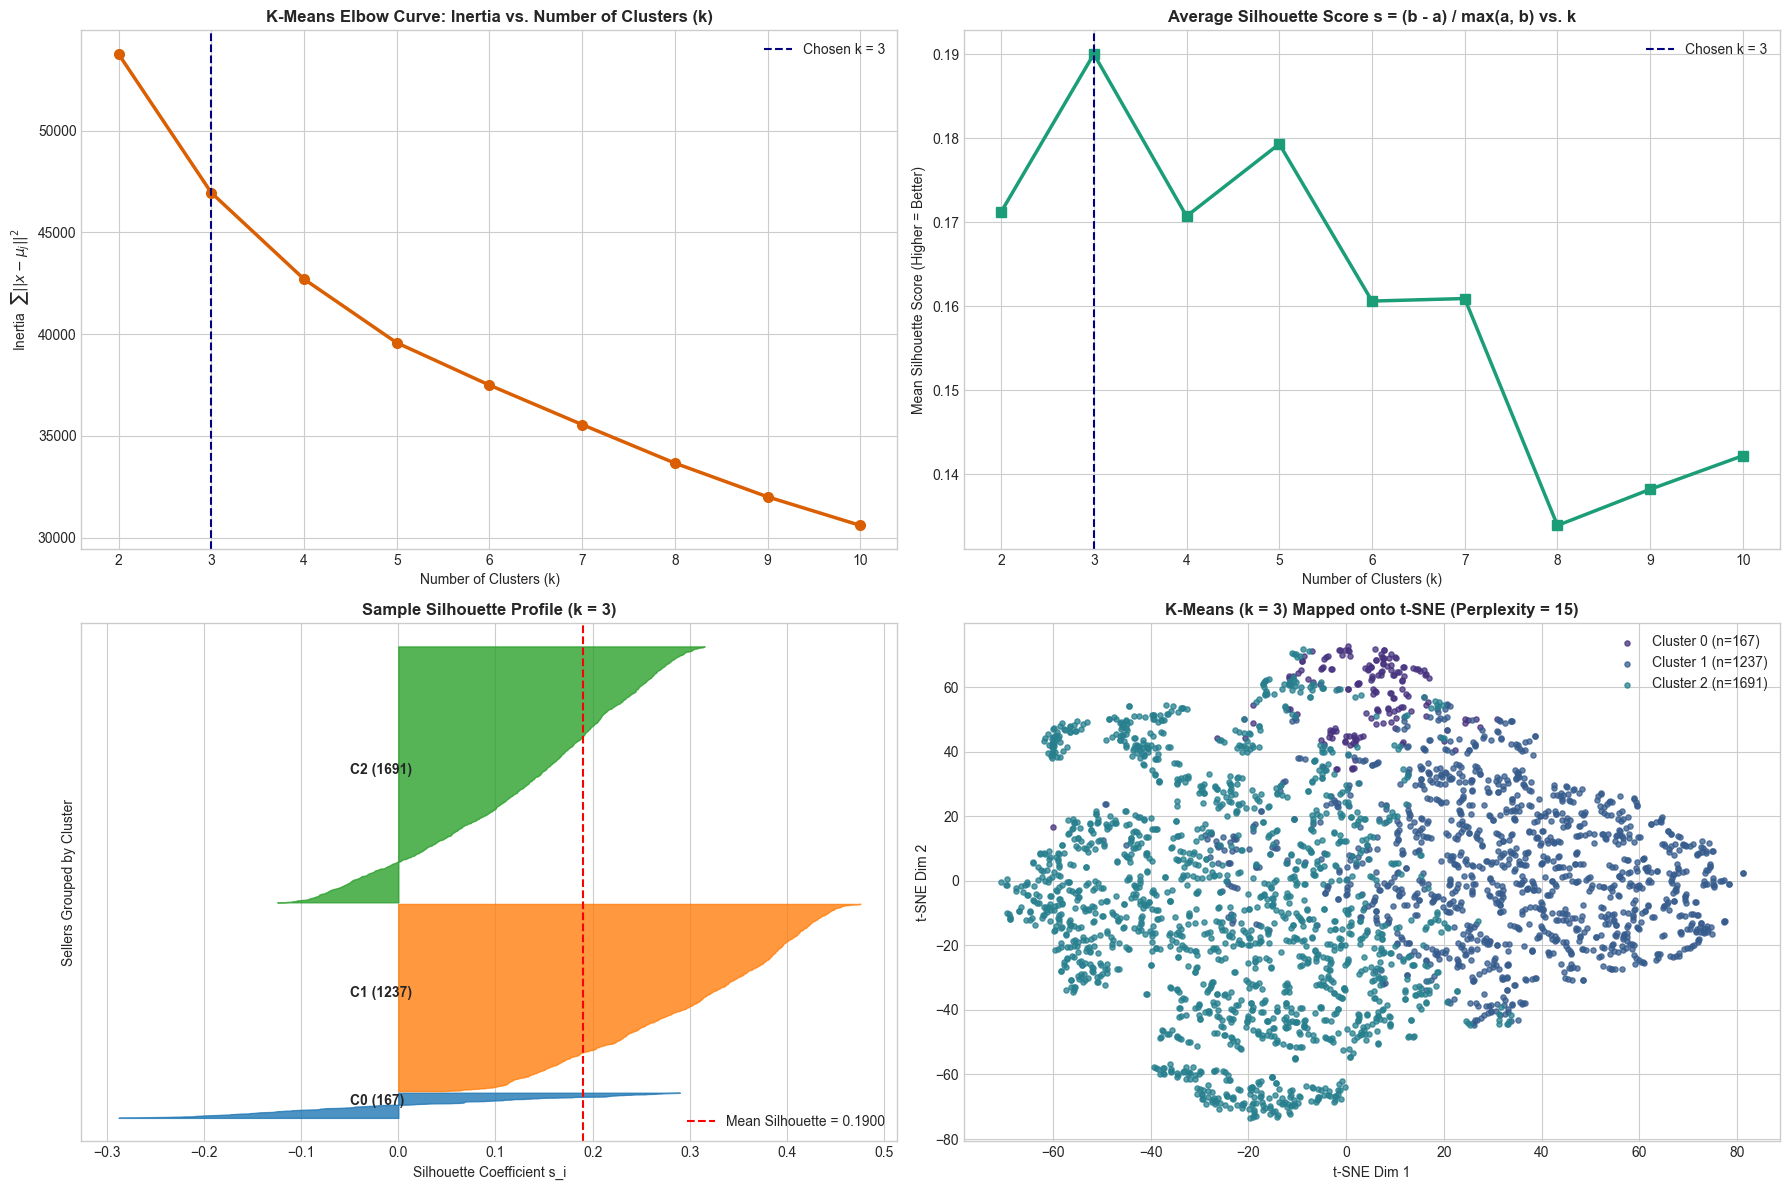

In [7]:
# ==============================================================================
# CELL 6: K-MEANS CLUSTERING — INERTIA, K-MEANS++, & SILHOUETTE ANALYSIS (LECTURE 19)
# ==============================================================================
from sklearn.metrics import silhouette_samples

# 1. Sweep k = 2 to 10 using k-means++ initialization and n_init=20 (Lecture 19 Slides 9-10)
k_values = range(2, 11)
kmeans_records = []
kmeans_models = {}

print("=== RUNNING K-MEANS SWEEP (k = 2 to 10 | init='k-means++', n_init=20) ===")
for k in k_values:
    km = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=20,
        max_iter=500,
        random_state=RANDOM_STATE
    )
    labels = km.fit_predict(X_mat)
    inertia = km.inertia_
    sil = silhouette_score(X_mat, labels)
    ch = calinski_harabasz_score(X_mat, labels)
    db = davies_bouldin_score(X_mat, labels)

    kmeans_models[k] = km
    kmeans_records.append({
        'k': k,
        'Inertia (WCSS)': round(inertia, 2),
        'Silhouette Score': round(sil, 4),
        'Calinski-Harabasz': round(ch, 2),
        'Davies-Bouldin': round(db, 4),
        'Iterations': km.n_iter_
    })
    print(f"k = {k:2d} | Inertia = {inertia:9.2f} | Silhouette = {sil:.4f} | "
          f"Davies-Bouldin = {db:.4f} | Converged in {km.n_iter_:2d} iters")

km_eval_df = pd.DataFrame(kmeans_records)

# 2. Select Optimal k (balancing Silhouette peak & business granularity k >= 3)
best_k_sil = int(km_eval_df.loc[km_eval_df['Silhouette Score'].idxmax(), 'k'])
# Also check best k among multi-segment business solutions (k >= 3)
multi_seg_df = km_eval_df[km_eval_df['k'] >= 3]
best_k_business = int(multi_seg_df.loc[multi_seg_df['Silhouette Score'].idxmax(), 'k'])

print(f"\nHighest overall Silhouette at k = {best_k_sil} (Score = {km_eval_df.loc[km_eval_df['k']==best_k_sil, 'Silhouette Score'].values[0]:.4f})")
print(f"Best multi-tier segmentation (k >= 3) at k = {best_k_business} (Score = {km_eval_df.loc[km_eval_df['k']==best_k_business, 'Silhouette Score'].values[0]:.4f})")

# Choose k = best_k_business (typically k=3 or k=4 for actionable seller tiers)
k_chosen_km = best_k_business
km_best = kmeans_models[k_chosen_km]
km_labels = km_best.labels_

# Cluster size breakdown
unique_c, counts_c = np.unique(km_labels, return_counts=True)
print(f"\n=== K-MEANS (k = {k_chosen_km}) CLUSTER DISTRIBUTION ===")
for cid, cnt in zip(unique_c, counts_c):
    print(f"Cluster {cid}: {cnt:4d} sellers ({cnt/len(km_labels)*100:5.2f}%)")

# 3. Visualization: Elbow Curve, Silhouette Curve, Silhouette Sample Diagram, & 2D Projections
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Panel A: Elbow Method — Inertia (Lecture 19 Slide 5 & 9)
axes[0, 0].plot(km_eval_df['k'], km_eval_df['Inertia (WCSS)'], 'o-', color='#d95f02', linewidth=2.5, markersize=7)
axes[0, 0].axvline(k_chosen_km, color='navy', linestyle='--', label=f'Chosen k = {k_chosen_km}')
axes[0, 0].set_title('K-Means Elbow Curve: Inertia vs. Number of Clusters (k)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Number of Clusters (k)')
axes[0, 0].set_ylabel('Inertia  $\sum ||x - \mu_j||^2$')
axes[0, 0].set_xticks(list(k_values))
axes[0, 0].legend()

# Panel B: Average Silhouette Score across k (Lecture 19 Slide 15)
axes[0, 1].plot(km_eval_df['k'], km_eval_df['Silhouette Score'], 's-', color='#1b9e77', linewidth=2.5, markersize=7)
axes[0, 1].axvline(k_chosen_km, color='navy', linestyle='--', label=f'Chosen k = {k_chosen_km}')
axes[0, 1].set_title('Average Silhouette Score s = (b - a) / max(a, b) vs. k', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Number of Clusters (k)')
axes[0, 1].set_ylabel('Mean Silhouette Score (Higher = Better)')
axes[0, 1].set_xticks(list(k_values))
axes[0, 1].legend()

# Panel C: Per-Sample Silhouette Plot for Chosen k (Lecture 19 Slide 15)
sample_sil_vals = silhouette_samples(X_mat, km_labels)
y_lower = 10
cmap_km = plt.cm.tab10
for i in range(k_chosen_km):
    ith_sil = np.sort(sample_sil_vals[km_labels == i])
    size_i = ith_sil.shape[0]
    y_upper = y_lower + size_i
    color = cmap_km(i)
    axes[1, 0].fill_betweenx(np.arange(y_lower, y_upper), 0, ith_sil, facecolor=color, edgecolor=color, alpha=0.8)
    axes[1, 0].text(-0.05, y_lower + 0.5 * size_i, f'C{i} ({size_i})', fontsize=10, fontweight='bold')
    y_lower = y_upper + 10

avg_sil = silhouette_score(X_mat, km_labels)
axes[1, 0].axvline(avg_sil, color='red', linestyle='--', linewidth=1.5, label=f'Mean Silhouette = {avg_sil:.4f}')
axes[1, 0].set_title(f'Sample Silhouette Profile (k = {k_chosen_km})', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Silhouette Coefficient s_i')
axes[1, 0].set_ylabel('Sellers Grouped by Cluster')
axes[1, 0].set_yticks([])
axes[1, 0].legend(loc='lower right')

# Panel D: K-Means Clusters Projected onto Optimal t-SNE Map (Perplexity = 15)
Y_tsne_best = tsne_results[best_perp]
for i in range(k_chosen_km):
    mask = (km_labels == i)
    axes[1, 1].scatter(Y_tsne_best[mask, 0], Y_tsne_best[mask, 1], s=14, alpha=0.75, label=f'Cluster {i} (n={mask.sum()})')
axes[1, 1].set_title(f'K-Means (k = {k_chosen_km}) Mapped onto t-SNE (Perplexity = {best_perp})', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('t-SNE Dim 1')
axes[1, 1].set_ylabel('t-SNE Dim 2')
axes[1, 1].legend()

plt.tight_layout()
km_fig_path = os.path.join(BASE_DIR, 'kmeans_analysis.png')
plt.savefig(km_fig_path, dpi=300, bbox_inches='tight')
print(f"\nSaved K-Means figure to: {km_fig_path}")
plt.show()

## Ward Hierarchial clustering

Ward linkage matrix computed! Shape: (3094, 4)

=== RUNNING WARD HIERARCHICAL CUTS (k = 2 to 10) ===
k =  2 | Silhouette = 0.1423 | Calinski-Harabasz =  548.41 | Davies-Bouldin = 1.9835
k =  3 | Silhouette = 0.1566 | Calinski-Harabasz =  495.71 | Davies-Bouldin = 1.8854
k =  4 | Silhouette = 0.1153 | Calinski-Harabasz =  415.50 | Davies-Bouldin = 2.0129
k =  5 | Silhouette = 0.1297 | Calinski-Harabasz =  382.13 | Davies-Bouldin = 1.8545
k =  6 | Silhouette = 0.1367 | Calinski-Harabasz =  357.88 | Davies-Bouldin = 1.8503
k =  7 | Silhouette = 0.1396 | Calinski-Harabasz =  338.14 | Davies-Bouldin = 1.8449
k =  8 | Silhouette = 0.1405 | Calinski-Harabasz =  325.72 | Davies-Bouldin = 1.6409
k =  9 | Silhouette = 0.0880 | Calinski-Harabasz =  319.23 | Davies-Bouldin = 1.7389
k = 10 | Silhouette = 0.0902 | Calinski-Harabasz =  307.23 | Davies-Bouldin = 1.6725

Highest Ward Silhouette at k = 3 (Score = 0.1566)

=== WARD HIERARCHICAL (k = 3) CLUSTER DISTRIBUTION ===
Ward Cluster 0: 1583 seller

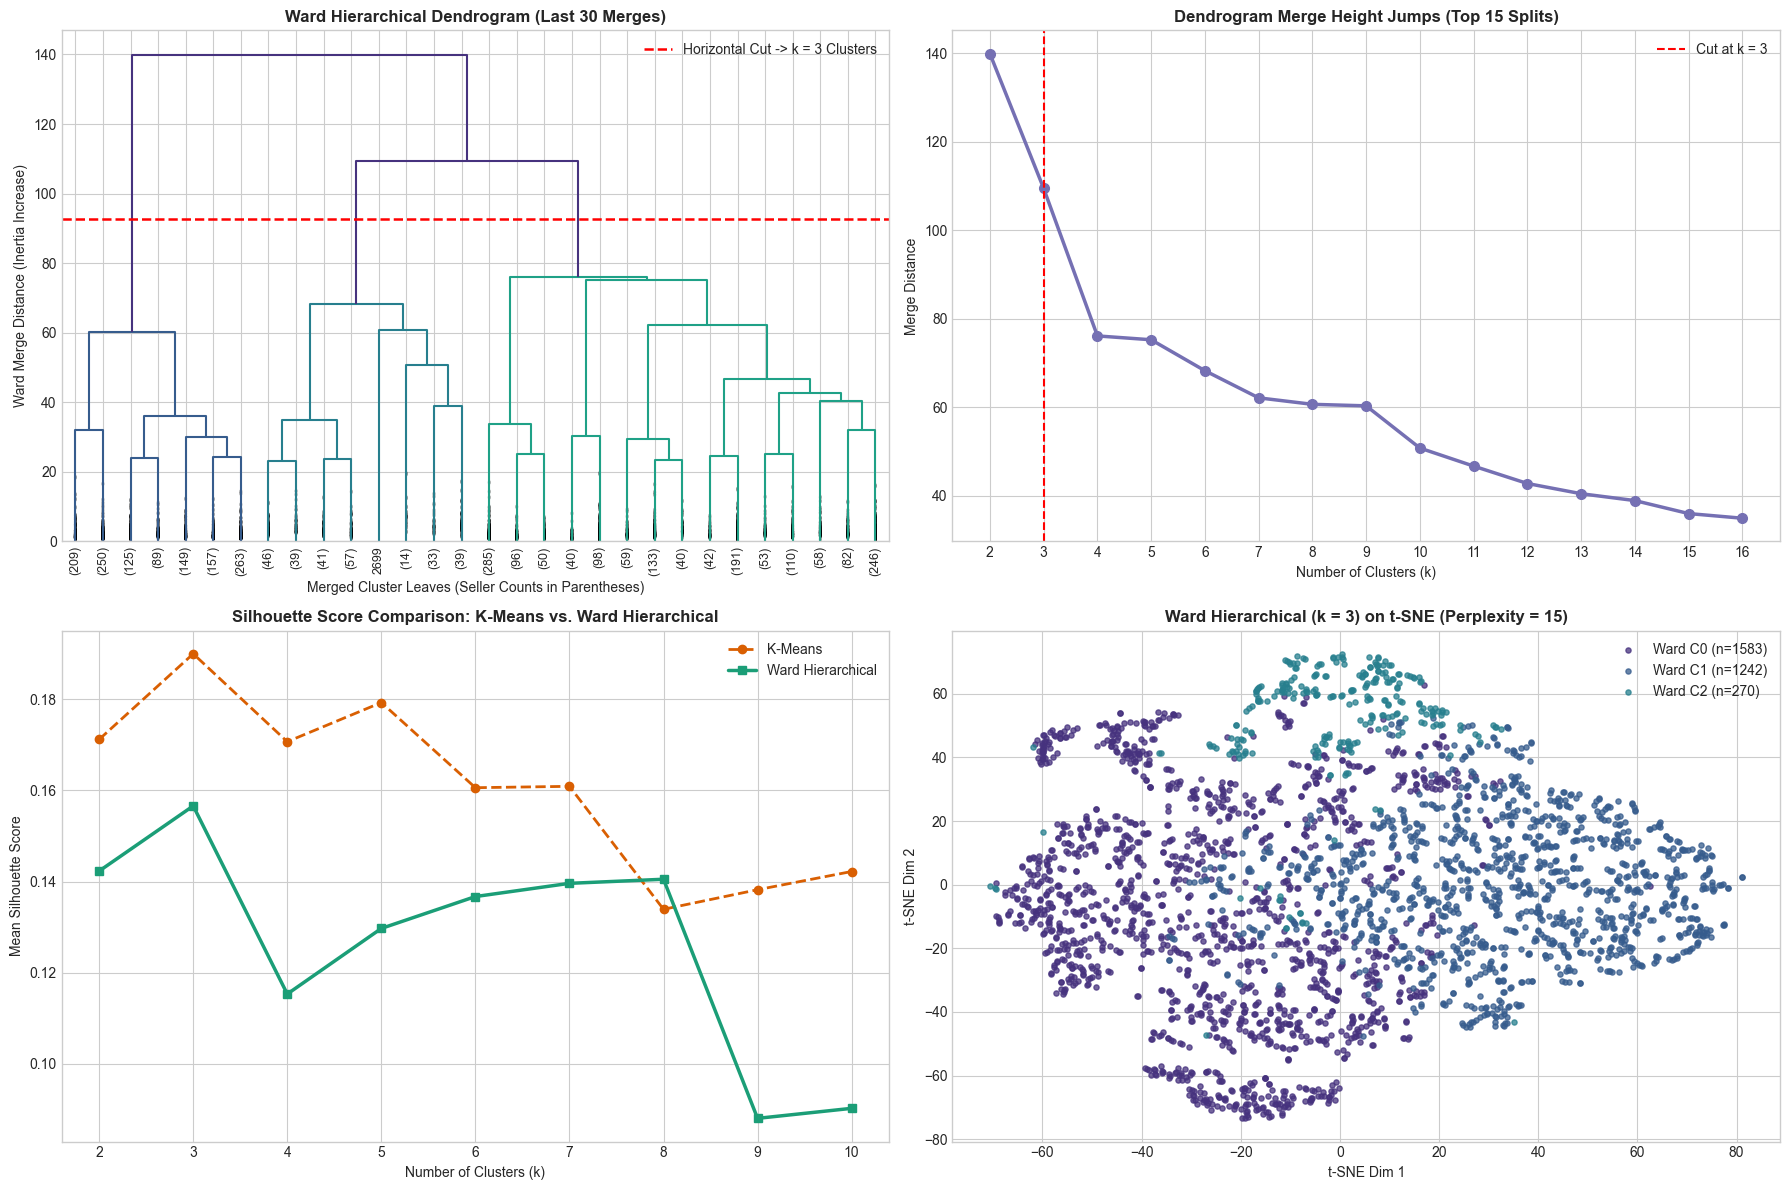

In [8]:
# ==============================================================================
# CELL 7: WARD HIERARCHICAL CLUSTERING & DENDROGRAM ANALYSIS (LECTURE 19 PART 2)
# ==============================================================================

# 1. Compute Ward Linkage Matrix (minimizes increase in total inertia at each merge)
Z_ward = linkage(X_mat, method='ward', metric='euclidean')
print("Ward linkage matrix computed! Shape:", Z_ward.shape)

# 2. Evaluate horizontal cuts across k = 2 to 10 (Lecture 19 Slide 18)
ward_records = []
ward_models = {}

print("\n=== RUNNING WARD HIERARCHICAL CUTS (k = 2 to 10) ===")
for k in range(2, 11):
    agg = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='ward')
    labels = agg.fit_predict(X_mat)
    sil = silhouette_score(X_mat, labels)
    ch = calinski_harabasz_score(X_mat, labels)
    db = davies_bouldin_score(X_mat, labels)

    ward_models[k] = agg
    ward_records.append({
        'k': k,
        'Silhouette Score': round(sil, 4),
        'Calinski-Harabasz': round(ch, 2),
        'Davies-Bouldin': round(db, 4)
    })
    print(f"k = {k:2d} | Silhouette = {sil:.4f} | Calinski-Harabasz = {ch:7.2f} | Davies-Bouldin = {db:.4f}")

ward_eval_df = pd.DataFrame(ward_records)
best_k_ward = int(ward_eval_df.loc[ward_eval_df['Silhouette Score'].idxmax(), 'k'])
ward_labels = ward_models[k_chosen_km].labels_  # Also inspect k=3 to compare head-to-head with K-Means

print(f"\nHighest Ward Silhouette at k = {best_k_ward} (Score = {ward_eval_df.loc[ward_eval_df['k']==best_k_ward, 'Silhouette Score'].values[0]:.4f})")
print(f"\n=== WARD HIERARCHICAL (k = {k_chosen_km}) CLUSTER DISTRIBUTION ===")
u_w, c_w = np.unique(ward_labels, return_counts=True)
for cid, cnt in zip(u_w, c_w):
    print(f"Ward Cluster {cid}: {cnt:4d} sellers ({cnt/len(ward_labels)*100:5.2f}%)")

# 3. Visualization: Truncated Ward Dendrogram + Merge Heights + Silhouette + t-SNE Projection
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Panel A: Truncated Ward Dendrogram (Top 30 merges for clarity)
cut_height = (Z_ward[-(k_chosen_km - 1), 2] + Z_ward[-k_chosen_km, 2]) / 2
dendrogram(
    Z_ward,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90.,
    leaf_font_size=9.,
    show_contracted=True,
    color_threshold=cut_height,
    ax=axes[0, 0]
)
axes[0, 0].axhline(cut_height, color='red', linestyle='--', linewidth=1.8, label=f'Horizontal Cut -> k = {k_chosen_km} Clusters')
axes[0, 0].set_title('Ward Hierarchical Dendrogram (Last 30 Merges)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Merged Cluster Leaves (Seller Counts in Parentheses)')
axes[0, 0].set_ylabel('Ward Merge Distance (Inertia Increase)')
axes[0, 0].legend()

# Panel B: Last 15 Merge Heights (Jump Method for Choosing k)
last_merges = Z_ward[-15:, 2][::-1]
merge_k = np.arange(2, 17)
axes[0, 1].plot(merge_k, last_merges, 'o-', color='#7570b3', linewidth=2.5, markersize=7)
axes[0, 1].axvline(k_chosen_km, color='red', linestyle='--', label=f'Cut at k = {k_chosen_km}')
axes[0, 1].set_title('Dendrogram Merge Height Jumps (Top 15 Splits)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Number of Clusters (k)')
axes[0, 1].set_ylabel('Merge Distance')
axes[0, 1].set_xticks(merge_k)
axes[0, 1].legend()

# Panel C: Silhouette Comparison — K-Means vs. Ward Hierarchical across k
axes[1, 0].plot(km_eval_df['k'], km_eval_df['Silhouette Score'], 'o--', color='#d95f02', linewidth=2, label='K-Means')
axes[1, 0].plot(ward_eval_df['k'], ward_eval_df['Silhouette Score'], 's-', color='#1b9e77', linewidth=2.5, label='Ward Hierarchical')
axes[1, 0].set_title('Silhouette Score Comparison: K-Means vs. Ward Hierarchical', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Number of Clusters (k)')
axes[1, 0].set_ylabel('Mean Silhouette Score')
axes[1, 0].set_xticks(range(2, 11))
axes[1, 0].legend()

# Panel D: Ward (k=3) Projected onto Optimal t-SNE Map
for i in range(k_chosen_km):
    mask = (ward_labels == i)
    axes[1, 1].scatter(Y_tsne_best[mask, 0], Y_tsne_best[mask, 1], s=14, alpha=0.75, label=f'Ward C{i} (n={mask.sum()})')
axes[1, 1].set_title(f'Ward Hierarchical (k = {k_chosen_km}) on t-SNE (Perplexity = {best_perp})', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('t-SNE Dim 1')
axes[1, 1].set_ylabel('t-SNE Dim 2')
axes[1, 1].legend()

plt.tight_layout()
ward_fig_path = os.path.join(BASE_DIR, 'ward_hierarchical_analysis.png')
plt.savefig(ward_fig_path, dpi=300, bbox_inches='tight')
print(f"\nSaved Ward Hierarchical figure to: {ward_fig_path}")
plt.show()

In [9]:
# ==============================================================================
# CELL 8: DBSCAN CLUSTERING — k-DISTANCE KNEE PLOT & CORE/BORDER/NOISE (LECTURE 20)
# ==============================================================================

def find_knee_eps(k_distances_sorted):
    """Automatically locate the knee (point of maximum perpendicular distance from chord)."""
    n_pts = len(k_distances_sorted)
    coords = np.vstack((np.arange(n_pts), k_distances_sorted)).T
    first_pt, last_pt = coords[0], coords[-1]
    line_vec = last_pt - first_pt
    line_vec_norm = line_vec / np.linalg.norm(line_vec)
    vec_from_first = coords - first_pt
    scalar_proj = vec_from_first @ line_vec_norm
    proj_vec = np.outer(scalar_proj, line_vec_norm)
    dist_to_line = np.linalg.norm(vec_from_first - proj_vec, axis=1)
    knee_idx = int(np.argmax(dist_to_line))
    return knee_idx, float(k_distances_sorted[knee_idx])

# ------------------------------------------------------------------------------
# 1. FULL 21D SPACE: minPts = 2 * d = 42 (Lecture 20 Slide 13 Rule of Thumb)
# ------------------------------------------------------------------------------
minPts_21d = 2 * X_mat.shape[1]  # 2 * 21 = 42
nn_21d = NearestNeighbors(n_neighbors=minPts_21d, metric='euclidean').fit(X_mat)
dists_21d, _ = nn_21d.kneighbors(X_mat)
k_dists_21d = np.sort(dists_21d[:, -1])
knee_idx_21d, eps_knee_21d = find_knee_eps(k_dists_21d)

print(f"=== DBSCAN STEP 1: 21D SPACE (minPts = 2*d = {minPts_21d}) ===")
print(f"Detected k-distance knee at index {knee_idx_21d} -> Suggested eps = {eps_knee_21d:.4f}")

# Sweep eps around the knee in 21D to inspect sensitivity
eps_sweep_21d = [round(eps_knee_21d * f, 2) for f in [0.65, 0.80, 0.90, 1.00, 1.15]]
print("\n21D Epsilon Sensitivity Sweep:")
for eps_val in eps_sweep_21d:
    db_tmp = DBSCAN(eps=eps_val, min_samples=minPts_21d).fit(X_mat)
    lbls = db_tmp.labels_
    n_clusters = len(set(lbls)) - (1 if -1 in lbls else 0)
    n_noise = int(np.sum(lbls == -1))
    non_noise = lbls != -1
    sil_str = f"{silhouette_score(X_mat[non_noise], lbls[non_noise]):.4f}" if n_clusters >= 2 else "N/A (<2 clusters)"
    print(f"  eps = {eps_val:5.2f} | Clusters = {n_clusters:2d} | Noise = {n_noise:4d} ({n_noise/len(lbls)*100:5.1f}%) | Silhouette (non-noise) = {sil_str}")

# Fit primary 21D DBSCAN at slightly tighter knee (0.80 * knee) or exact knee to capture dense cores + outliers
dbscan_21d = DBSCAN(eps=round(eps_knee_21d * 0.80, 2), min_samples=minPts_21d).fit(X_mat)
db_labels_21d = dbscan_21d.labels_

# Classify Core, Border, and Noise points (Lecture 20 Slide 10)
core_mask_21d = np.zeros_like(db_labels_21d, dtype=bool)
core_mask_21d[dbscan_21d.core_sample_indices_] = True
noise_mask_21d = (db_labels_21d == -1)
border_mask_21d = (~core_mask_21d) & (~noise_mask_21d)

print(f"\n=== 21D DBSCAN POINT CLASSIFICATION (eps = {round(eps_knee_21d * 0.80, 2)}, minPts = {minPts_21d}) ===")
print(f"Core Points   : {core_mask_21d.sum():4d} ({core_mask_21d.mean()*100:5.2f}%)")
print(f"Border Points : {border_mask_21d.sum():4d} ({border_mask_21d.mean()*100:5.2f}%)")
print(f"Noise (-1)    : {noise_mask_21d.sum():4d} ({noise_mask_21d.mean()*100:5.2f}%)")

=== DBSCAN STEP 1: 21D SPACE (minPts = 2*d = 42) ===
Detected k-distance knee at index 2963 -> Suggested eps = 5.4616

21D Epsilon Sensitivity Sweep:
  eps =  3.55 | Clusters =  1 | Noise =  197 (  6.4%) | Silhouette (non-noise) = N/A (<2 clusters)
  eps =  4.37 | Clusters =  1 | Noise =  100 (  3.2%) | Silhouette (non-noise) = N/A (<2 clusters)
  eps =  4.92 | Clusters =  1 | Noise =   69 (  2.2%) | Silhouette (non-noise) = N/A (<2 clusters)
  eps =  5.46 | Clusters =  1 | Noise =   37 (  1.2%) | Silhouette (non-noise) = N/A (<2 clusters)
  eps =  6.28 | Clusters =  1 | Noise =   17 (  0.5%) | Silhouette (non-noise) = N/A (<2 clusters)

=== 21D DBSCAN POINT CLASSIFICATION (eps = 4.37, minPts = 42) ===
Core Points   : 2822 (91.18%)
Border Points :  173 ( 5.59%)
Noise (-1)    :  100 ( 3.23%)


## DBSCAN

=== 6D AUTOENCODER LATENT SPACE DBSCAN (eps = 2.201, minPts = 12) ===
Clusters found: 1 | Noise (-1): 136 (4.39%)

Saved DBSCAN figure to: E:\DA_Project\dbscan_analysis.png


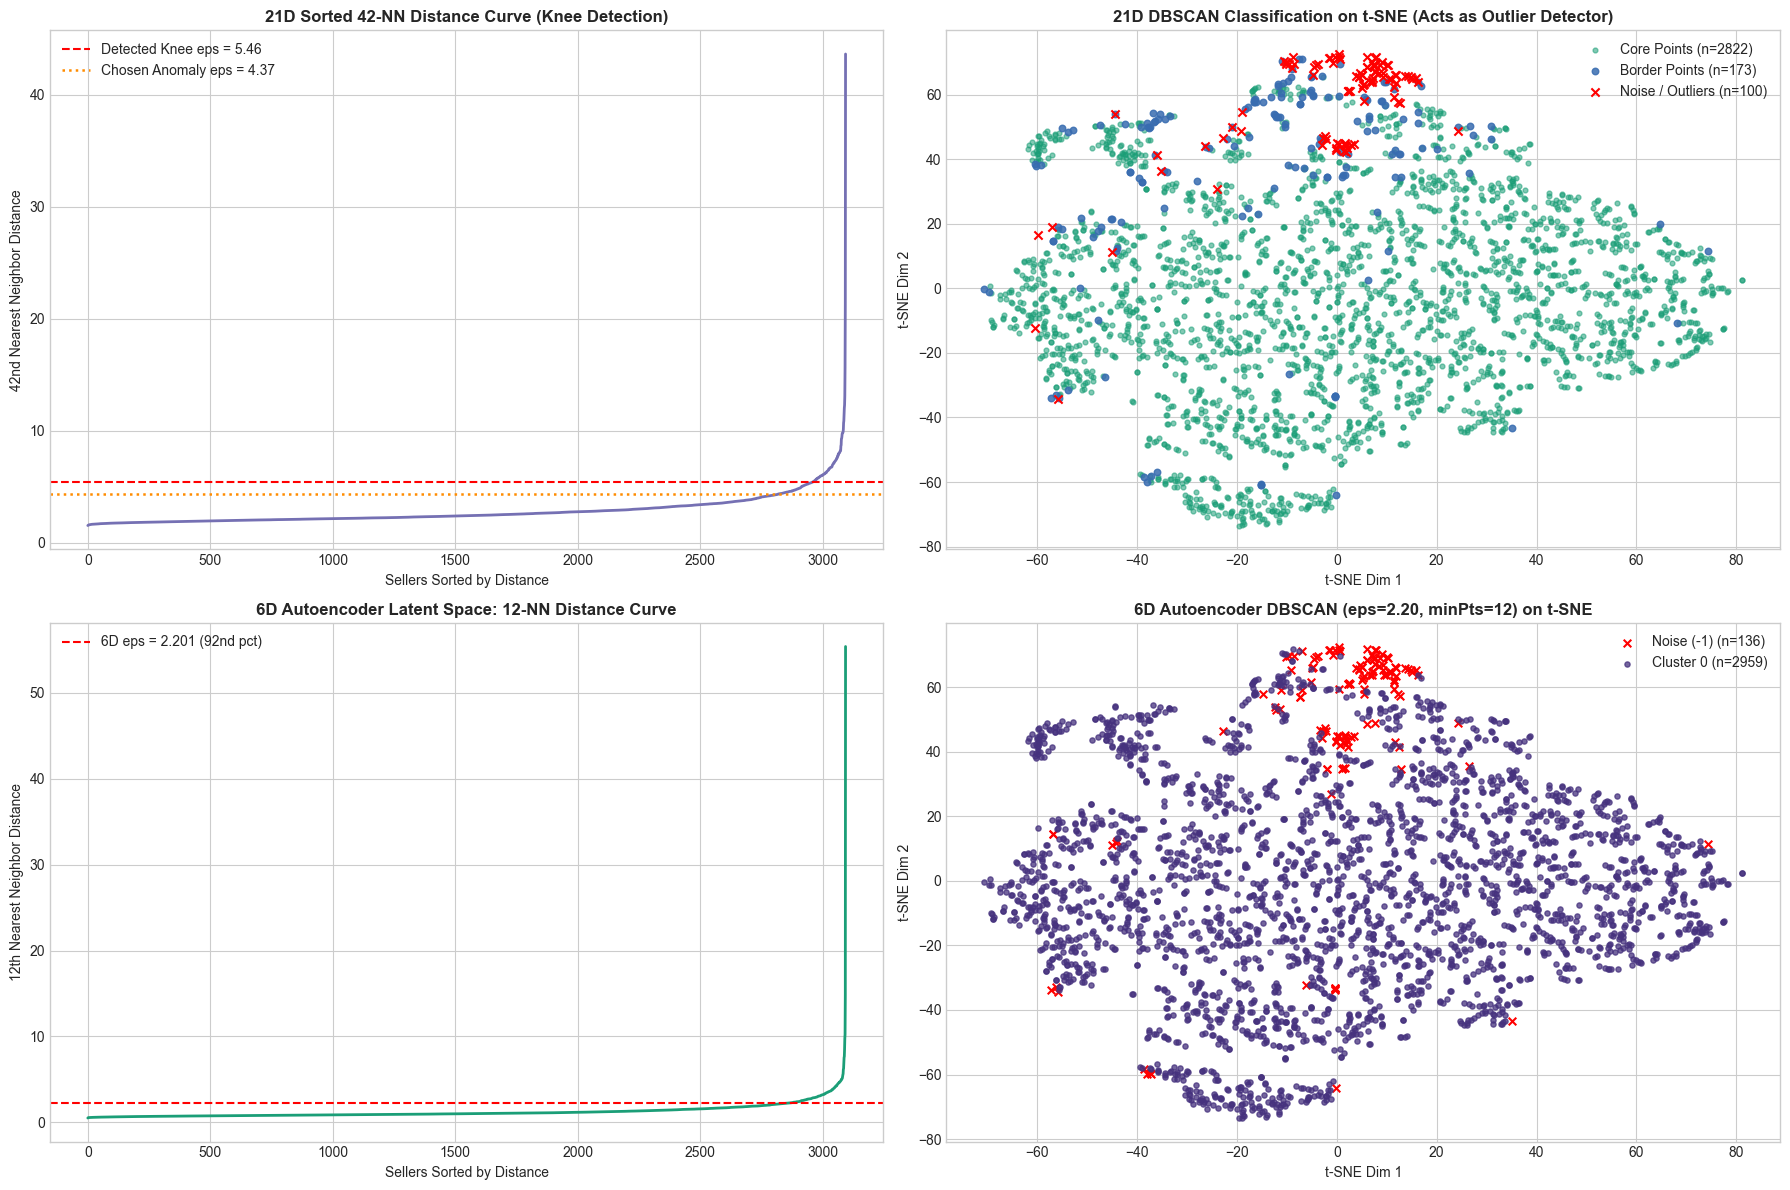

In [10]:
# ==============================================================================
# CELL 8B: DBSCAN VISUALIZATION (k-DISTANCE KNEE + 21D vs. 6D LATENT SPACE)
# ==============================================================================

# 1. Re-compute 21D k-distance curve & 21D DBSCAN labels (eps = 4.37, minPts = 42)
min_pts_21d = 42
nbrs_21d = NearestNeighbors(n_neighbors=min_pts_21d).fit(X_mat)
dists_21d, _ = nbrs_21d.kneighbors(X_mat)
k_dists_21d = np.sort(dists_21d[:, -1])

dbscan_21d = DBSCAN(eps=4.37, min_samples=min_pts_21d)
db_labels_21d = dbscan_21d.fit_predict(X_mat)

# Identify Core, Border, and Noise (-1) masks for 21D
core_mask_21d = np.zeros_like(db_labels_21d, dtype=bool)
core_mask_21d[dbscan_21d.core_sample_indices_] = True
noise_mask_21d = (db_labels_21d == -1)
border_mask_21d = (~core_mask_21d) & (~noise_mask_21d)

# 2. Also run DBSCAN in 6D Autoencoder Latent Space (minPts = 2*6 = 12)
min_pts_6d = 12
nbrs_6d = NearestNeighbors(n_neighbors=min_pts_6d).fit(Z_ae_6d)
dists_6d, _ = nbrs_6d.kneighbors(Z_ae_6d)
k_dists_6d = np.sort(dists_6d[:, -1])

# Pick eps near the 92nd percentile knee of 6D k-distances
eps_6d = float(np.percentile(k_dists_6d, 92))
dbscan_6d = DBSCAN(eps=eps_6d, min_samples=min_pts_6d)
db_labels_6d = dbscan_6d.fit_predict(Z_ae_6d)

n_clusters_6d = len(set(db_labels_6d)) - (1 if -1 in db_labels_6d else 0)
n_noise_6d = int((db_labels_6d == -1).sum())
print(f"=== 6D AUTOENCODER LATENT SPACE DBSCAN (eps = {eps_6d:.3f}, minPts = {min_pts_6d}) ===")
print(f"Clusters found: {n_clusters_6d} | Noise (-1): {n_noise_6d} ({n_noise_6d/len(db_labels_6d)*100:.2f}%)")
if n_clusters_6d >= 2:
    non_noise = db_labels_6d != -1
    print(f"Silhouette (non-noise): {silhouette_score(Z_ae_6d[non_noise], db_labels_6d[non_noise]):.4f}")

# 3. 2x2 Visualization Grid
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Panel A: 21D k-Distance Knee Plot
axes[0, 0].plot(k_dists_21d, color='#7570b3', linewidth=2)
axes[0, 0].axhline(5.4616, color='red', linestyle='--', label='Detected Knee eps = 5.46')
axes[0, 0].axhline(4.37, color='darkorange', linestyle=':', linewidth=1.8, label='Chosen Anomaly eps = 4.37')
axes[0, 0].set_title('21D Sorted 42-NN Distance Curve (Knee Detection)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Sellers Sorted by Distance')
axes[0, 0].set_ylabel('42nd Nearest Neighbor Distance')
axes[0, 0].legend()

# Panel B: 21D DBSCAN Point Types (Core vs. Border vs. Noise) on t-SNE
axes[0, 1].scatter(Y_tsne_best[core_mask_21d, 0], Y_tsne_best[core_mask_21d, 1],
                   c='#1b9e77', s=12, alpha=0.55, label=f'Core Points (n={core_mask_21d.sum()})')
axes[0, 1].scatter(Y_tsne_best[border_mask_21d, 0], Y_tsne_best[border_mask_21d, 1],
                   c='#386cb0', s=22, alpha=0.85, label=f'Border Points (n={border_mask_21d.sum()})')
axes[0, 1].scatter(Y_tsne_best[noise_mask_21d, 0], Y_tsne_best[noise_mask_21d, 1],
                   c='red', marker='x', s=35, linewidths=1.5, label=f'Noise / Outliers (n={noise_mask_21d.sum()})')
axes[0, 1].set_title('21D DBSCAN Classification on t-SNE (Acts as Outlier Detector)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('t-SNE Dim 1')
axes[0, 1].set_ylabel('t-SNE Dim 2')
axes[0, 1].legend()

# Panel C: 6D Autoencoder k-Distance Knee Plot
axes[1, 0].plot(k_dists_6d, color='#1b9e77', linewidth=2)
axes[1, 0].axhline(eps_6d, color='red', linestyle='--', label=f'6D eps = {eps_6d:.3f} (92nd pct)')
axes[1, 0].set_title('6D Autoencoder Latent Space: 12-NN Distance Curve', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Sellers Sorted by Distance')
axes[1, 0].set_ylabel('12th Nearest Neighbor Distance')
axes[1, 0].legend()

# Panel D: 6D DBSCAN Clusters on t-SNE
for cid in sorted(set(db_labels_6d)):
    mask = (db_labels_6d == cid)
    if cid == -1:
        axes[1, 1].scatter(Y_tsne_best[mask, 0], Y_tsne_best[mask, 1], c='red', marker='x', s=30, label=f'Noise (-1) (n={mask.sum()})')
    else:
        axes[1, 1].scatter(Y_tsne_best[mask, 0], Y_tsne_best[mask, 1], s=14, alpha=0.75, label=f'Cluster {cid} (n={mask.sum()})')
axes[1, 1].set_title(f'6D Autoencoder DBSCAN (eps={eps_6d:.2f}, minPts={min_pts_6d}) on t-SNE', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('t-SNE Dim 1')
axes[1, 1].set_ylabel('t-SNE Dim 2')
axes[1, 1].legend()

plt.tight_layout()
dbscan_fig_path = os.path.join(BASE_DIR, 'dbscan_analysis.png')
plt.savefig(dbscan_fig_path, dpi=300, bbox_inches='tight')
print(f"\nSaved DBSCAN figure to: {dbscan_fig_path}")
plt.show()

## Mean shift Clustering

=== RUNNING MEAN-SHIFT BANDWIDTH SWEEP (21D STANDARDIZED SPACE) ===
Quantile = 0.10 | Bandwidth = 3.931 | Clusters =   7 | Largest =  90.8% | Silhouette = 0.2408
Quantile = 0.15 | Bandwidth = 4.231 | Clusters =   9 | Largest =  93.6% | Silhouette = 0.2571
Quantile = 0.20 | Bandwidth = 4.479 | Clusters =   9 | Largest =  93.5% | Silhouette = 0.2546
Quantile = 0.25 | Bandwidth = 4.701 | Clusters =   7 | Largest =  96.1% | Silhouette = 0.3328
Quantile = 0.30 | Bandwidth = 4.909 | Clusters =   8 | Largest =  95.6% | Silhouette = 0.3194

Selected Mean-Shift Quantile = 0.25 (Clusters = 7, Silhouette = 0.3328)

Top Mean-Shift Cluster Sizes:
  Mode  0: 2975 sellers (96.12%)
  Mode  1:   86 sellers ( 2.78%)
  Mode  3:   14 sellers ( 0.45%)
  Mode  5:    9 sellers ( 0.29%)
  Mode  6:    7 sellers ( 0.23%)
  Mode  2:    3 sellers ( 0.10%)

Saved Mean-Shift figure to: E:\DA_Project\meanshift_analysis.png


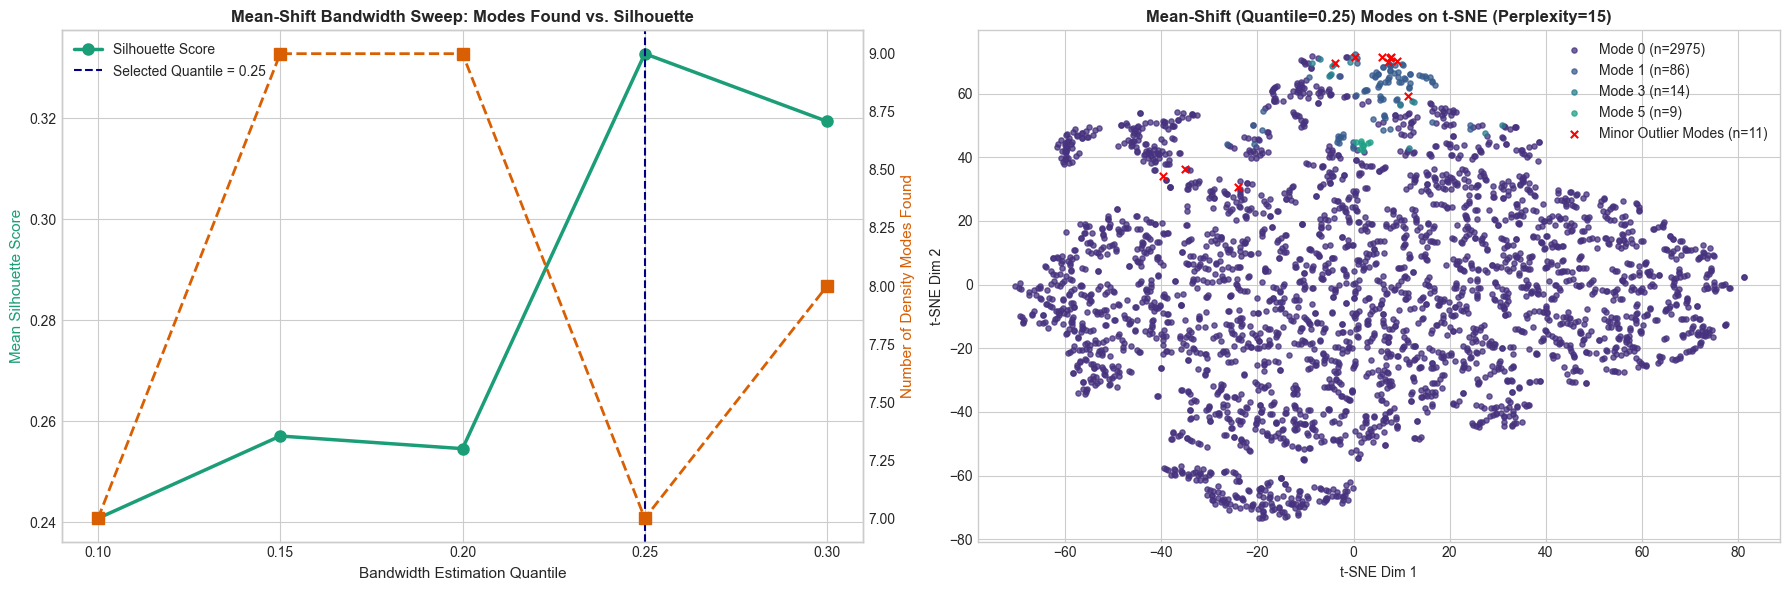

In [11]:
# ==============================================================================
# CELL 9: MEAN-SHIFT CLUSTERING — BANDWIDTH ESTIMATION & MODE SEEKING
# ==============================================================================

# 1. Sweep bandwidth quantiles to see how kernel radius controls number of modes
quantiles = [0.10, 0.15, 0.20, 0.25, 0.30]
ms_records = []
ms_models = {}

print("=== RUNNING MEAN-SHIFT BANDWIDTH SWEEP (21D STANDARDIZED SPACE) ===")
for q in quantiles:
    bw = estimate_bandwidth(X_mat, quantile=q, n_samples=1500, random_state=RANDOM_STATE)
    ms = MeanShift(bandwidth=bw, bin_seeding=True, n_jobs=-1)
    labels = ms.fit_predict(X_mat)

    n_clusters = len(np.unique(labels))
    largest_share = (np.bincount(labels).max() / len(labels)) * 100
    sil = silhouette_score(X_mat, labels) if n_clusters >= 2 else np.nan
    ch = calinski_harabasz_score(X_mat, labels) if n_clusters >= 2 else np.nan
    db = davies_bouldin_score(X_mat, labels) if n_clusters >= 2 else np.nan

    ms_models[q] = ms
    ms_records.append({
        'Quantile': q,
        'Bandwidth (h)': round(bw, 4),
        'Clusters Found': n_clusters,
        'Largest Cluster (%)': round(largest_share, 2),
        'Silhouette Score': round(sil, 4) if not np.isnan(sil) else np.nan,
        'Calinski-Harabasz': round(ch, 2) if not np.isnan(ch) else np.nan,
        'Davies-Bouldin': round(db, 4) if not np.isnan(db) else np.nan
    })
    print(f"Quantile = {q:.2f} | Bandwidth = {bw:.3f} | Clusters = {n_clusters:3d} | "
          f"Largest = {largest_share:5.1f}% | Silhouette = {sil:.4f}")

ms_eval_df = pd.DataFrame(ms_records)

# 2. Pick representative quantile (q = 0.20 standard default, or best Silhouette with >=2 clusters)
valid_ms = ms_eval_df[ms_eval_df['Clusters Found'] >= 2]
best_q_ms = float(valid_ms.loc[valid_ms['Silhouette Score'].idxmax(), 'Quantile'])
ms_best = ms_models[best_q_ms]
ms_labels = ms_best.labels_

print(f"\nSelected Mean-Shift Quantile = {best_q_ms:.2f} "
      f"(Clusters = {len(np.unique(ms_labels))}, Silhouette = {valid_ms.loc[valid_ms['Quantile']==best_q_ms, 'Silhouette Score'].values[0]:.4f})")

# Print top 5 largest Mean-Shift modes
ms_counts = pd.Series(ms_labels).value_counts()
print("\nTop Mean-Shift Cluster Sizes:")
for cid, cnt in ms_counts.head(6).items():
    print(f"  Mode {cid:2d}: {cnt:4d} sellers ({cnt/len(ms_labels)*100:5.2f}%)")

# 3. Visualization: Bandwidth vs. Clusters/Silhouette + Top Modes Projected on t-SNE
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Panel A: Bandwidth Quantile Trade-off (Clusters Found vs. Silhouette Score)
ax1 = axes[0]
ax1.plot(ms_eval_df['Quantile'], ms_eval_df['Silhouette Score'], 'o-', color='#1b9e77', linewidth=2.5, markersize=8, label='Silhouette Score')
ax1.axvline(best_q_ms, color='navy', linestyle='--', label=f'Selected Quantile = {best_q_ms:.2f}')
ax1.set_xlabel('Bandwidth Estimation Quantile', fontsize=11)
ax1.set_ylabel('Mean Silhouette Score', fontsize=11, color='#1b9e77')
ax1.set_xticks(quantiles)
ax1.legend(loc='upper left')

ax2 = ax1.twinx()
ax2.plot(ms_eval_df['Quantile'], ms_eval_df['Clusters Found'], 's--', color='#d95f02', linewidth=2, markersize=8, label='Clusters Found')
ax2.set_ylabel('Number of Density Modes Found', fontsize=11, color='#d95f02')
ax2.grid(False)
ax1.set_title('Mean-Shift Bandwidth Sweep: Modes Found vs. Silhouette', fontsize=12, fontweight='bold')

# Panel B: Mean-Shift Modes on Optimal t-SNE Map (Highlighting Top 4 Modes + Micro-Modes)
top_modes = ms_counts.head(4).index.tolist()
for cid in top_modes:
    mask = (ms_labels == cid)
    axes[1].scatter(Y_tsne_best[mask, 0], Y_tsne_best[mask, 1], s=14, alpha=0.75, label=f'Mode {cid} (n={mask.sum()})')

other_mask = ~np.isin(ms_labels, top_modes)
if other_mask.sum() > 0:
    axes[1].scatter(Y_tsne_best[other_mask, 0], Y_tsne_best[other_mask, 1], c='red', marker='x', s=28,
                    label=f'Minor Outlier Modes (n={other_mask.sum()})')

axes[1].set_title(f'Mean-Shift (Quantile={best_q_ms:.2f}) Modes on t-SNE (Perplexity={best_perp})', fontsize=12, fontweight='bold')
axes[1].set_xlabel('t-SNE Dim 1')
axes[1].set_ylabel('t-SNE Dim 2')
axes[1].legend()

plt.tight_layout()
ms_fig_path = os.path.join(BASE_DIR, 'meanshift_analysis.png')
plt.savefig(ms_fig_path, dpi=300, bbox_inches='tight')
print(f"\nSaved Mean-Shift figure to: {ms_fig_path}")
plt.show()

## OPTICS

=== 21D Standardized Space OPTICS (minPts=25, xi=0.04) ===
  Mean Core Distance         : 2.6203 (Median: 2.2431)
  Mean Reachability Distance : 2.1350 (Max: 33.7375)
  Xi-Extracted Clusters      : 1 | Noise (-1): 0 (0.00%)
  Silhouette (non-noise)     : N/A (<2 clusters)
  Cluster Distribution       : {0: np.int64(3095)}

=== 6D Autoencoder Space OPTICS  (minPts=20, xi=0.04) ===
  Mean Core Distance         : 1.4130 (Median: 1.1111)
  Mean Reachability Distance : 1.1308 (Max: 47.8729)
  Xi-Extracted Clusters      : 1 | Noise (-1): 0 (0.00%)
  Silhouette (non-noise)     : N/A (<2 clusters)
  Cluster Distribution       : {0: np.int64(3095)}

Horizontal Cut Check (Slide 5): Cutting 21D reachability at eps' = 3.068 -> 1 cluster(s), 310 noise points.

Saved OPTICS figure to: E:\DA_Project\optics_analysis.png


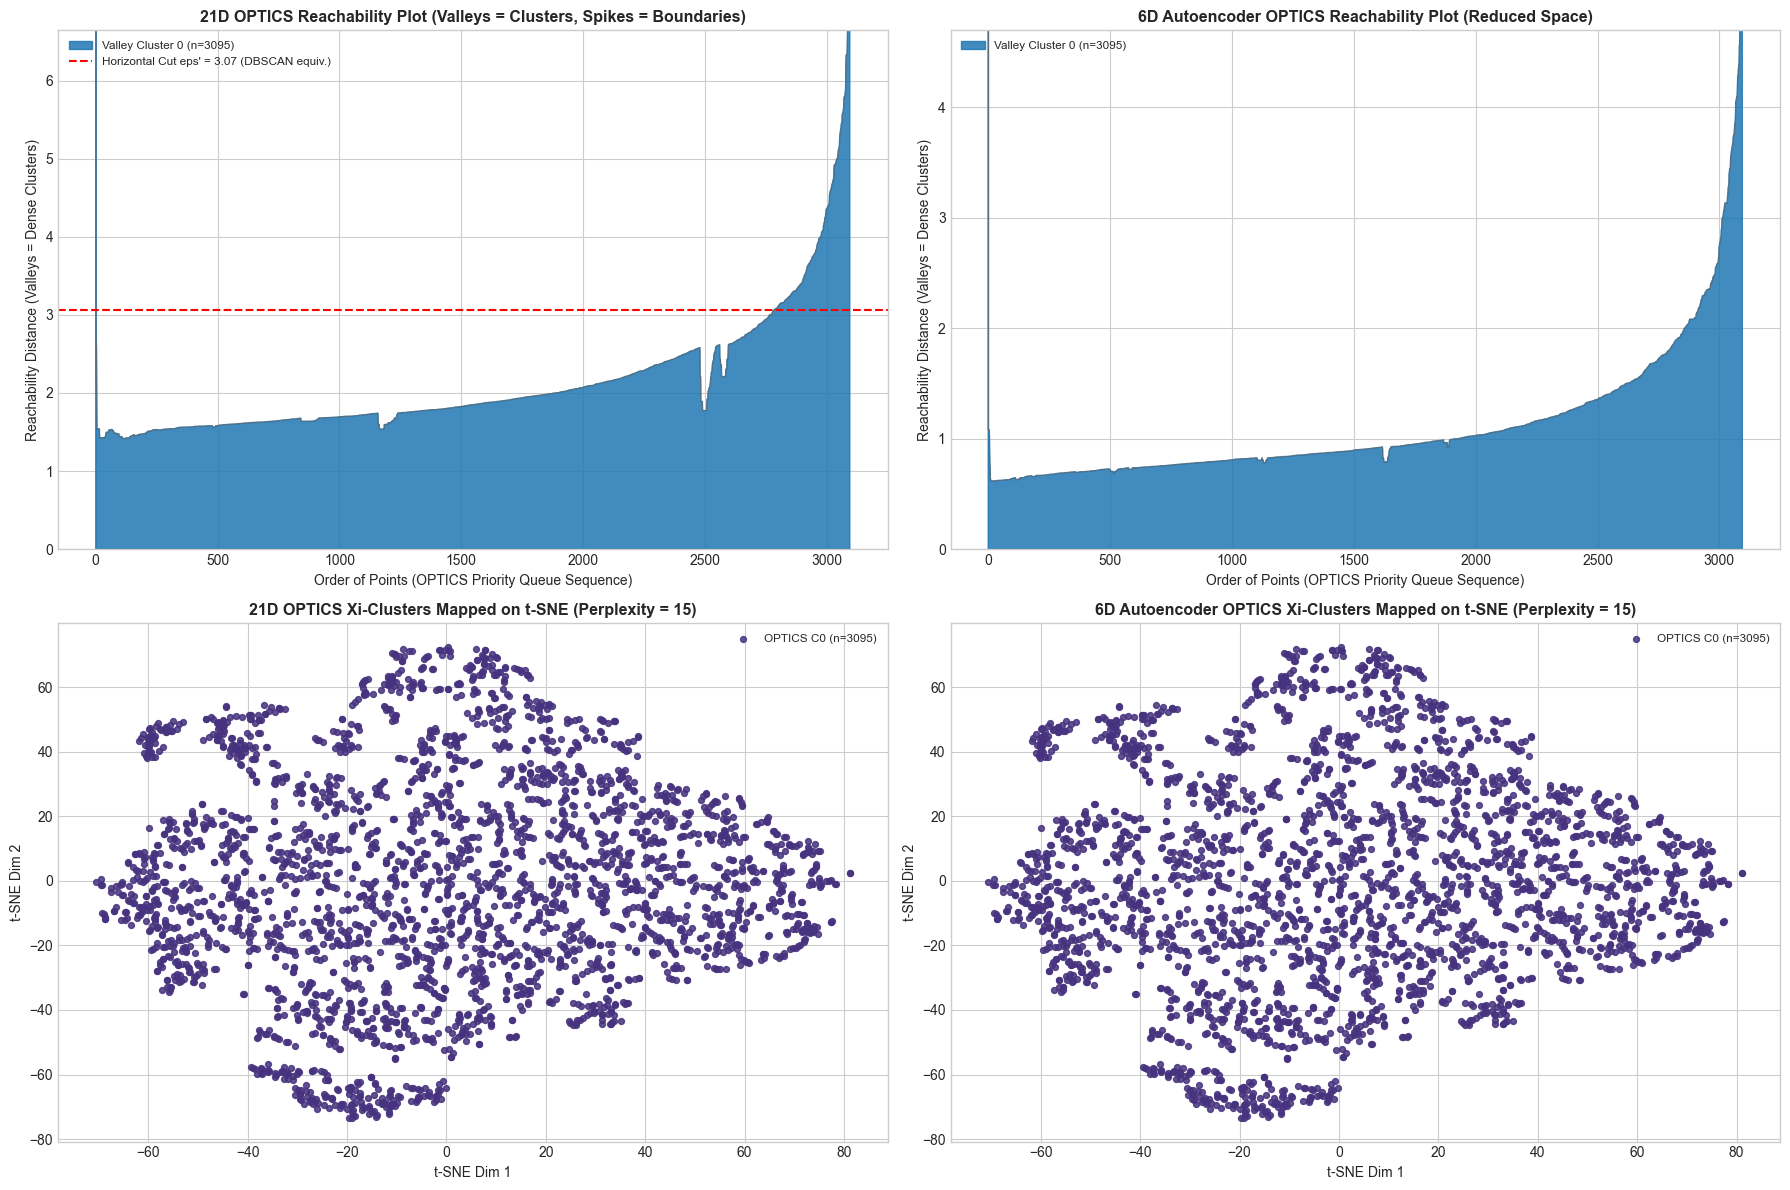

In [12]:
# ==============================================================================
# CELL 10: OPTICS CLUSTERING — CORE/REACHABILITY DISTANCES & VALLEYS (LECTURE 21)
# ==============================================================================
from sklearn.cluster import cluster_optics_dbscan

# 1. Fit OPTICS in 21D Standardized Space (Lecture 21 Slides 3-4)
# max_eps=np.inf ensures every point's full reachability ordering is computed without artificial cutoff
optics_21d = OPTICS(
    min_samples=25,
    max_eps=np.inf,
    metric='euclidean',
    cluster_method='xi',
    xi=0.04,
    min_cluster_size=0.015,
    n_jobs=-1
)
opt_labels_21d = optics_21d.fit_predict(X_mat)

# 2. Fit OPTICS in 6D Autoencoder Latent Space (reduces high-dimensional distance concentration, Slide 2)
optics_6d = OPTICS(
    min_samples=20,
    max_eps=np.inf,
    metric='euclidean',
    cluster_method='xi',
    xi=0.04,
    min_cluster_size=0.015,
    n_jobs=-1
)
opt_labels_6d = optics_6d.fit_predict(Z_ae_6d)

# 3. Also demonstrate Slide 5 property: "A cut at height eps' gives DBSCAN at eps'"
eps_prime_21d = float(np.percentile(optics_21d.reachability_[np.isfinite(optics_21d.reachability_)], 90))
opt_dbscan_cut_21d = cluster_optics_dbscan(
    reachability=optics_21d.reachability_,
    core_distances=optics_21d.core_distances_,
    ordering=optics_21d.ordering_,
    eps=eps_prime_21d
)

def summarize_optics(name, X_space, opt_model, labels):
    reach_finite = opt_model.reachability_[np.isfinite(opt_model.reachability_)]
    core_finite = opt_model.core_distances_[np.isfinite(opt_model.core_distances_)]
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = int((labels == -1).sum())
    noise_pct = n_noise / len(labels) * 100
    non_noise = (labels != -1)

    if n_clusters >= 2 and non_noise.sum() > n_clusters:
        sil = silhouette_score(X_space[non_noise], labels[non_noise])
        ch = calinski_harabasz_score(X_space[non_noise], labels[non_noise])
        db = davies_bouldin_score(X_space[non_noise], labels[non_noise])
        sil_str = f"{sil:.4f}"
    else:
        sil, ch, db = np.nan, np.nan, np.nan
        sil_str = "N/A (<2 clusters)"

    print(f"=== {name} ===")
    print(f"  Mean Core Distance         : {core_finite.mean():.4f} (Median: {np.median(core_finite):.4f})")
    print(f"  Mean Reachability Distance : {reach_finite.mean():.4f} (Max: {reach_finite.max():.4f})")
    print(f"  Xi-Extracted Clusters      : {n_clusters} | Noise (-1): {n_noise} ({noise_pct:.2f}%)")
    print(f"  Silhouette (non-noise)     : {sil_str}")
    print(f"  Cluster Distribution       : {dict(pd.Series(labels).value_counts().sort_index())}\n")
    return n_clusters, n_noise, sil, ch, db

opt_stats_21d = summarize_optics("21D Standardized Space OPTICS (minPts=25, xi=0.04)", X_mat, optics_21d, opt_labels_21d)
opt_stats_6d  = summarize_optics("6D Autoencoder Space OPTICS  (minPts=20, xi=0.04)", Z_ae_6d, optics_6d, opt_labels_6d)

print(f"Horizontal Cut Check (Slide 5): Cutting 21D reachability at eps' = {eps_prime_21d:.3f} -> "
      f"{len(set(opt_dbscan_cut_21d)) - (1 if -1 in opt_dbscan_cut_21d else 0)} cluster(s), "
      f"{(opt_dbscan_cut_21d == -1).sum()} noise points.")

# ------------------------------------------------------------------------------
# 4. VISUALIZATION: FILLED REACHABILITY PLOTS (SLIDE 6) & t-SNE EMBEDDINGS
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

def plot_optics_reachability_slide6(ax, opt_model, labels, title, eps_cut=None):
    """Filled reachability valley plot matching Lecture 21 Slide 6."""
    order = opt_model.ordering_
    reach = opt_model.reachability_[order].copy()
    ordered_lbls = labels[order]

    # Replace inf at index 0 (start point, Slide 4 Step 1) with max finite reachability for clean plotting
    finite_max = np.nanmax(reach[np.isfinite(reach)])
    reach[~np.isfinite(reach)] = finite_max * 1.05
    x_idx = np.arange(len(reach))

    # Plot baseline curve
    ax.plot(x_idx, reach, color='dimgray', linewidth=0.8, alpha=0.7)

    # Fill valleys by cluster label (Lecture 21 Slide 6)
    unique_lbls = sorted(set(ordered_lbls))
    cmap = plt.cm.tab10
    color_idx = 0
    for lbl in unique_lbls:
        mask = (ordered_lbls == lbl)
        if lbl == -1:
            ax.fill_between(x_idx, 0, reach, where=mask, color='lightgray', alpha=0.65,
                            label=f'Noise / Peaks (-1) (n={mask.sum()})')
        else:
            ax.fill_between(x_idx, 0, reach, where=mask, color=cmap(color_idx % 10), alpha=0.85,
                            label=f'Valley Cluster {lbl} (n={mask.sum()})')
            color_idx += 1

    if eps_cut is not None:
        ax.axhline(eps_cut, color='red', linestyle='--', linewidth=1.5,
                   label=f"Horizontal Cut eps' = {eps_cut:.2f} (DBSCAN equiv.)")

    ax.set_ylim(0, np.percentile(reach, 99.2) * 1.15)
    ax.set_title(title, fontsize=11.5, fontweight='bold')
    ax.set_xlabel('Order of Points (OPTICS Priority Queue Sequence)')
    ax.set_ylabel('Reachability Distance (Valleys = Dense Clusters)')
    ax.legend(loc='upper left', fontsize=8.5)

# Panel A: 21D Reachability Plot
plot_optics_reachability_slide6(
    axes[0, 0], optics_21d, opt_labels_21d,
    '21D OPTICS Reachability Plot (Valleys = Clusters, Spikes = Boundaries)',
    eps_cut=eps_prime_21d
)

# Panel B: 6D Autoencoder Reachability Plot
plot_optics_reachability_slide6(
    axes[0, 1], optics_6d, opt_labels_6d,
    '6D Autoencoder OPTICS Reachability Plot (Reduced Space)'
)

# Panel C: 21D OPTICS Clusters on t-SNE
for lbl in sorted(set(opt_labels_21d)):
    mask = (opt_labels_21d == lbl)
    if lbl == -1:
        axes[1, 0].scatter(Y_tsne_best[mask, 0], Y_tsne_best[mask, 1], c='lightgray', s=10, alpha=0.45,
                           label=f'Noise (-1) (n={mask.sum()})')
    else:
        axes[1, 0].scatter(Y_tsne_best[mask, 0], Y_tsne_best[mask, 1], s=18, alpha=0.85,
                           label=f'OPTICS C{lbl} (n={mask.sum()})')
axes[1, 0].set_title(f'21D OPTICS Xi-Clusters Mapped on t-SNE (Perplexity = {best_perp})', fontsize=11.5, fontweight='bold')
axes[1, 0].set_xlabel('t-SNE Dim 1')
axes[1, 0].set_ylabel('t-SNE Dim 2')
axes[1, 0].legend(fontsize=8.5)

# Panel D: 6D Autoencoder OPTICS Clusters on t-SNE
for lbl in sorted(set(opt_labels_6d)):
    mask = (opt_labels_6d == lbl)
    if lbl == -1:
        axes[1, 1].scatter(Y_tsne_best[mask, 0], Y_tsne_best[mask, 1], c='lightgray', s=10, alpha=0.45,
                           label=f'Noise (-1) (n={mask.sum()})')
    else:
        axes[1, 1].scatter(Y_tsne_best[mask, 0], Y_tsne_best[mask, 1], s=18, alpha=0.85,
                           label=f'OPTICS C{lbl} (n={mask.sum()})')
axes[1, 1].set_title(f'6D Autoencoder OPTICS Xi-Clusters Mapped on t-SNE (Perplexity = {best_perp})', fontsize=11.5, fontweight='bold')
axes[1, 1].set_xlabel('t-SNE Dim 1')
axes[1, 1].set_ylabel('t-SNE Dim 2')
axes[1, 1].legend(fontsize=8.5)

plt.tight_layout()
optics_fig_path = os.path.join(BASE_DIR, 'optics_analysis.png')
plt.savefig(optics_fig_path, dpi=300, bbox_inches='tight')
print(f"\nSaved OPTICS figure to: {optics_fig_path}")
plt.show()